# Task 18 — Late-delivery risk in a global supply chain: which orders to expedite

**Study unit:** ARI3217 — AI Enterprise Architectures and Transformation (University of Malta)
**Dataset:** [DataCo Smart Supply Chain for Big Data Analysis](https://www.kaggle.com/datasets/shashwatwork/dataco-smart-supply-chain-for-big-data-analysis) (order lines, column descriptions and a product clickstream; Constante, Silva and Pereira, Mendeley Data, 2019)
**Task family:** tabular supervised learning, a capacity-constrained queue, temporal validation and drift · **Companion task:** `02_card_fraud_tabular.ipynb` (the same forward evaluation and capacity-based operating point, on a balanced label with a generator behind it)

---

## The task card

> **Board question.** *About 57 orders leave our checkout every day and 54 % ship later than promised: 31 broken promises a day. The warehouse can expedite 15 a day. Which 15 should it pick as orders are placed, how many late orders does that save, and is a model worth more than the shift lead's rule of thumb, or than changing the promise?*

**Business context.** DataCo sells sports goods, clothing and electronics to five world markets. Each shipping mode carries a promise: dispatch within 0 (Same Day), 1 (First Class), 2 (Second Class) or 4 days (Standard). The model joins a legacy estate: the order-management system (OMS), the warehouse, the carriers and the CRM. Session 01's *online prediction* pattern: `POST /risk` scores each order as it is placed, and the shift lead works the expedite queue (*human-in-the-loop*).

**What you will build from this notebook (see *Student tasks* at the end):**

1. the given **order-risk model**, packaged and reproducible, scored at placement and evaluated *forward in time*, with the traps guarded by tests;
2. an **expedite queue** sized by capacity and costed, against a change to the promise;
3. the **operational wrapper**: package, tests, CI gate, registry, model card, monitoring;
4. a small **knowledge base** of products, routes and promises, with SHACL and an ablation.

**Where this sits in the unit**

| Block | What this task exercises |
|---|---|
| 1 · EA for AI | Scoring in the order flow (OMS → warehouse → carrier → CRM); human-in-the-loop queue; AI Act and GDPR |
| 2 · MLOps | Forward validation, recall at capacity as the gate, label maturity, harmless and harmful drift |
| 3 · Semantic layer | Product and route hierarchies with SHACL; the promise as a fact; the ablation |
| 4 · LLM/RAG | An operations copilot that explains the risk and drafts the customer notification |

**Assessment.** A *worked baseline plus tasks*; marks follow `docs/task-rubric.md`. The model is given: you are marked on how you package, evaluate, deploy, monitor and govern it, not on improving it. The notebook contains **deliberate traps**, each flagged with ⚠ in the text; turning each into a test is part of the task.

**Honesty note.** Presented as DataCo Global's records, the data behaves like a **generator**: orders every 21 minutes, markets served in blocks of months, dispatch times uniform within each shipping mode. We treat it as synthetic; that makes the ceiling of any model visible, and the promise, not the model, the main lesson.

---

## How this notebook is organised

The notebook has three parts. Parts A and B are given; Part C is your assignment. **The model is given:** you package, evaluate, deploy and monitor it; you do not design, tune or replace it.

| Part | Sections | What it contains | What you do with it |
|---|---|---|---|
| **A · Explore the data** | 1–2 | Dataset card and first look: a promise, a clock and a die | Read. Its quirks go into your model card and data contract. |
| **B · The given model** | 3–5 | Features known at placement, the model against the rules, the daily queue and the promise, the traps | Read, then package the code unchanged and reproduce its numbers (C2). |
| **C · Productionise it** | 6–10 | The model after deployment, the knowledge base and context pack, the module spine, student tasks, hand-in checklist | Your work: package, test, gate, track, serve, monitor, govern. Section 6 shows the drift your monitoring must weigh. |

**What you need from Parts A and B**

- **Code to package:** `get_raw`, `pseudonym`, `load_lines` and `load_clicks` (Section 1); `customer_history`, `build_features`, `fit`, `untie`, `daily_queue`, `evaluate` and `rule_score` (Section 3); `policy_row` (Section 4); `psi_cat` and `psi_num` for monitoring (Section 6); `node` and `sparql` for the knowledge base (Section 7).
- **Parameters for `config/config.yaml`:** the CAPITALS in Section 0.
- **Numbers your pipeline must reproduce (C2):** 31,249 training orders, 10,514 validation and 15,586 test (Jan – Sep 2017, the frozen CI holdout); test AUPRC 0.812 against 0.809 for the rule by mode and half-day; a queue of 15 a day catches 41.9 % of late orders at 86.8 % precision; €451 a day for the model queue against €622 with no expediting.
- **Runtime:** about 1–2 minutes on a laptop (84 s on the build machine).

## 0 · Setup

*Before Part A · the parameters below move into `config/config.yaml`.*

In [1]:
%matplotlib inline
import os, json, time, hashlib, warnings
from pathlib import Path
from urllib.parse import quote

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
import sklearn
import rdflib
import pyshacl
from rdflib import Graph, Literal, Namespace, RDF
from IPython.display import display
from sklearn.metrics import average_precision_score, roc_auc_score, precision_recall_curve
from sklearn.model_selection import train_test_split

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 140); pd.set_option("display.max_columns", 20); pd.set_option("display.max_colwidth", 60)

# ---- parameters -------------------------------------------------------------
SEED = 3217
N_JOBS = 1                                # one thread: faster on a shared laptop, and deterministic
KAGGLE_HANDLE = "shashwatwork/dataco-smart-supply-chain-for-big-data-analysis"
WINDOW_START, WINDOW_END = pd.Timestamp("2015-01-01"), pd.Timestamp("2018-02-01")   # order dates: all of the data
TRAIN_END = pd.Timestamp("2016-07-01")    # train: orders placed Jan 2015 – Jun 2016
VALID_END = pd.Timestamp("2017-01-01")    # validation (operating point): Jul – Dec 2016
TEST_END = pd.Timestamp("2017-10-01")     # test, the frozen CI holdout: Jan – Sep 2017 · stream: Oct 2017 – Jan 2018
LABEL_MATURITY_DAYS = 7                   # an order's outcome is known once it has shipped (at most 6 days here)
EXPEDITE_PER_DAY = 15                     # orders operations can expedite a day (assumption — task C3)
EXPEDITE_COST_EUR = 6.0                   # carrier upgrade or priority pick, per order (assumption — task C3)
LATE_COST_EUR = 20.0                      # contact centre, voucher, churn risk, per late order (assumption — task C3)
PROMISE_QUANTILE = 0.75                   # policy simulation: quote each mode's promise at this quantile of dispatch days
GATE_MIN_RECALL = 0.40                    # CI gate: recall at capacity on the holdout (placeholder for the business)
GATE_AUPRC_MARGIN = 0.01                  # CI gate: AUPRC may be at most this far below the rule (non-inferiority)
N_BOOT = 200                              # day-bootstrap resamples for the gate's intervals
PSI_ALERT = 0.25

DATA_DIR = Path(os.environ.get("DATASETS_TASKS_DATA", Path.cwd().parent.parent / "data"))
RAW, PROCESSED = DATA_DIR / "raw" / "dataco", DATA_DIR / "processed"
RAW.mkdir(parents=True, exist_ok=True); PROCESSED.mkdir(parents=True, exist_ok=True)

SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
INK, MUTED, GRID = "#0b0b0b", "#898781", "#e1e0d9"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c3c2b7",
    "axes.labelcolor": "#52514e", "xtick.color": MUTED, "ytick.color": MUTED, "text.color": INK,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.spines.top": False,
    "axes.spines.right": False, "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "legend.frameon": False, "figure.dpi": 110,
})
MODES = ["First Class", "Same Day", "Second Class", "Standard Class"]
MCOL = dict(zip(MODES, SERIES))
np.random.seed(SEED)
T_START = time.time()
print(f"pandas {pd.__version__} · lightgbm {lgb.__version__} · scikit-learn {sklearn.__version__} · "
      f"numpy {np.__version__} · rdflib {rdflib.__version__} · pyshacl {pyshacl.__version__}")

pandas 3.1.0 · lightgbm 4.7.0 · scikit-learn 1.9.1 · numpy 2.5.4 · rdflib 7.6.0 · pyshacl 0.40.1


# Part A — Explore the data

*Sections 1–2: read them; the quirks they find go into your model card and data contract.*

## 1 · Dataset card

*Part A · Explore · read; package `get_raw`, `pseudonym`, `load_lines` and `load_clicks`.*

| Field | Value |
|---|---|
| **Source** | Kaggle `shashwatwork/dataco-smart-supply-chain-for-big-data-analysis`, from Mendeley Data (Constante, Silva and Pereira, 2019) |
| **Licence** | **CC BY 4.0** (the Mendeley Data original, doi:10.17632/8gx2fvg2k6.5). Kaggle says CC0, but a re-upload cannot waive attribution: credit Constante, Silva and Pereira (2019) |
| **Provenance** | Presented as one company's supply-chain records; generated in behaviour (quirk 5) |
| **Size** | 180,519 order lines in 65,752 orders from 20,652 customers, placed 1 Jan 2015 – 31 Jan 2018; 469,977 page views of 76 products, 1 Sep 2017 – 31 Jan 2018 |
| **Files** | `DataCoSupplyChainDataset.csv` (95.9 MB, Latin-1), `tokenized_access_logs.csv` (95.4 MB), `DescriptionDataCoSupplyChain.csv` (column descriptions) |
| **Schema (lines)** | shipping mode, scheduled and real days, statuses, payment `Type`, product and destination hierarchies, price, discount, profit, customer fields |
| **Label** | `Late_delivery_risk`, 54.8 % of orders: *real days > scheduled days* for every order that shipped; 0 for the 4.3 % that never shipped |
| **Window used here** | All of it (33 MB in memory). Train on orders placed Jan 2015 – Jun 2016, validate Jul – Dec 2016, test Jan – Sep 2017 (frozen CI holdout); stream Oct 2017 – Jan 2018 |
| **PII** | Customer names, address and coordinates **never read**; email and password masked (checked on load); customer ID replaced by a keyed hash; clickstream IP addresses not loaded |

**Known quirks you must handle (and should mention in your model card):**

1. ⚠ **The label is a rule on two columns.** Real days and the shipping date are written at dispatch, when the label is decided (Trap 1).
2. ⚠ **Orders that never ship are "not late".** `CANCELED` and `SUSPECTED_FRAUD` orders carry label 0 (Traps 2, 4 and 5).
3. ⚠ **`Type` is the order status in disguise:** each status maps to exactly one payment type (Trap 2).
4. **Label, mode and status belong to the order:** its 2.75 lines never disagree. Model and split orders.
5. **A clockwork generator.** 84 % of orders are exactly 21 minutes apart; markets are served one at a time (Section 6); dispatch days are uniform within a mode in every market (Trap 6).
6. **A new catalogue in October 2017:** 99 % of orders have one line (20 % before), 99 % are in unseen categories, 99 % come from new customers (Section 6).
7. **Names lie.** `Sales per customer` equals the line total and `Benefit per order` the line-level `Order Profit Per Order` (checked on load). Countries are in Spanish (`Francia`); labels carry stray spaces (Section 7).
8. **The clickstream covers only Sep 2017 – Jan 2018**; 72 of its 76 products match the catalogue.

In [2]:
PERSONAL = ["Customer Fname", "Customer Lname", "Customer Email", "Customer Password", "Customer Street",
            "Customer City", "Customer State", "Customer Zipcode", "Customer Country", "Latitude", "Longitude"]
NOT_USED = ["Product Description", "Product Image", "Product Status", "Order Customer Id", "Order Zipcode",
            "Product Category Id", "Order Item Cardprod Id", "Product Price", "Sales per customer", "Benefit per order"]
RENAME = {"Type": "pay_type", "Days for shipping (real)": "real_days", "Days for shipment (scheduled)": "promise_days",
          "Delivery Status": "delivery_status", "Late_delivery_risk": "late", "Category Id": "category_id",
          "Category Name": "category", "Customer Id": "customer_id", "Customer Segment": "segment",
          "Department Id": "dept_id", "Department Name": "dept", "Market": "market", "Order City": "city",
          "Order Country": "country", "order date (DateOrders)": "placed", "Order Id": "order_id",
          "Order Item Discount": "discount", "Order Item Discount Rate": "discount_rate", "Order Item Id": "line_id",
          "Order Item Product Price": "price", "Order Item Profit Ratio": "profit_ratio", "Order Item Quantity": "quantity",
          "Sales": "sales", "Order Item Total": "line_total", "Order Profit Per Order": "line_profit",
          "Order Region": "region", "Order State": "state", "Order Status": "status", "Product Card Id": "product_id",
          "Product Name": "product", "shipping date (DateOrders)": "shipped", "Shipping Mode": "mode"}

def get_raw(filename: str) -> Path:
    local = RAW / filename
    if local.exists():
        return local
    import kagglehub
    return Path(kagglehub.dataset_download(KAGGLE_HANDLE, path=filename))

def pseudonym(ids: pd.Series) -> pd.Series:
    """Keyed hash of the customer ID: joins still work, the shop's ID does not leave this frame."""
    key = os.environ.get("DATACO_PSEUDONYM_KEY", "teaching-only-key").encode()     # production: a secret store
    lut = {i: hashlib.blake2b(str(i).encode(), key=key, digest_size=6).hexdigest() for i in ids.unique()}
    return ids.map(lut)

def load_lines() -> pd.DataFrame:
    cache = PROCESSED / "18_dataco_lines.parquet"
    if cache.exists():
        return pd.read_parquet(cache)
    t = time.time()
    path = get_raw("DataCoSupplyChainDataset.csv")
    header = pd.read_csv(path, encoding="latin-1", nrows=0).columns
    df = pd.read_csv(path, encoding="latin-1", usecols=[c for c in header if c not in PERSONAL + NOT_USED])
    df = df.rename(columns=RENAME)                           # the personal columns were never read
    df["customer"] = pseudonym(df.customer_id)
    df = df.drop(columns="customer_id")
    for c in ["placed", "shipped"]:
        df[c] = pd.to_datetime(df[c], format="%m/%d/%Y %H:%M")
    df = df[(df.placed >= WINDOW_START) & (df.placed < WINDOW_END)]
    for c in ["pay_type", "delivery_status", "category", "segment", "dept", "market", "city", "country", "region",
              "state", "status", "product", "mode"]:
        df[c] = df[c].astype("category")
    df = df.sort_values(["placed", "order_id", "line_id"]).reset_index(drop=True)
    df.to_parquet(cache)
    print(f"loaded + cached in {time.time()-t:.0f}s")
    return df

def load_clicks() -> pd.DataFrame:
    cache = PROCESSED / "18_dataco_clicks.parquet"
    if cache.exists():
        return pd.read_parquet(cache)
    cols = ["Product", "Category", "Department", "Date"]                 # the `ip` column is never read
    ck = pd.read_csv(get_raw("tokenized_access_logs.csv"), usecols=cols)
    ck["ts"] = pd.to_datetime(ck.pop("Date"), format="%m/%d/%Y %H:%M")
    ck = ck.rename(columns=str.lower)
    for c in ["product", "category", "department"]:
        ck[c] = ck[c].astype("category")
    ck.to_parquet(cache)
    return ck

lines = load_lines()
clicks = load_clicks()
desc = pd.read_csv(get_raw("DescriptionDataCoSupplyChain.csv"), encoding="latin-1")
desc = pd.Series(desc.DESCRIPTION.str.lstrip(": ").str.strip().values, index=desc.FIELDS.str.strip().str.lower())
checks = pd.read_csv(get_raw("DataCoSupplyChainDataset.csv"), encoding="latin-1",   # masked or duplicate columns, read once to verify
                     usecols=["Customer Email", "Customer Password", "Sales per customer", "Order Item Total",
                              "Benefit per order", "Order Profit Per Order"])
print(f"{len(lines):,} order lines · {lines.order_id.nunique():,} orders · {lines.customer.nunique():,} customers (pseudonymised) · "
      f"orders placed {lines.placed.min():%d %b %Y} – {lines.placed.max():%d %b %Y} · late {lines.late.mean():.1%} of lines · "
      f"{lines.memory_usage(deep=True).sum()/1e6:.0f} MB")
print(f"clickstream: {len(clicks):,} product page views of {clicks['product'].nunique()} products, {clicks.ts.min():%d %b %Y} – {clicks.ts.max():%d %b %Y} "
      f"(IP addresses not loaded) · email and password columns: {checks['Customer Email'].nunique()} and "
      f"{checks['Customer Password'].nunique()} distinct value(s) — masked")
print(f"'Sales per customer' == 'Order Item Total' on {(checks['Sales per customer'] == checks['Order Item Total']).mean():.0%} of lines · "
      f"'Benefit per order' == 'Order Profit Per Order' on {(checks['Benefit per order'] == checks['Order Profit Per Order']).mean():.0%} (both dropped)")
print("files: " + " · ".join(f"{f} {get_raw(f).stat().st_size / 1e6:.1f} MB" for f in
                             ["DataCoSupplyChainDataset.csv", "tokenized_access_logs.csv", "DescriptionDataCoSupplyChain.csv"]))
del checks

180,519 order lines · 65,752 orders · 20,652 customers (pseudonymised) · orders placed 01 Jan 2015 – 31 Jan 2018 · late 54.8% of lines · 33 MB
clickstream: 469,977 product page views of 76 products, 01 Sep 2017 – 31 Jan 2018 (IP addresses not loaded) · email and password columns: 1 and 1 distinct value(s) — masked
'Sales per customer' == 'Order Item Total' on 100% of lines · 'Benefit per order' == 'Order Profit Per Order' on 100% (both dropped)
files: DataCoSupplyChainDataset.csv 95.9 MB · tokenized_access_logs.csv 95.4 MB · DescriptionDataCoSupplyChain.csv 0.0 MB


In [3]:
# One row per order: the shipping decision, the label and the status are properties of the order, not of the line
g = lines.groupby("order_id", sort=False)
print(f"lines per order: mean {g.size().mean():.2f}, max {g.size().max()} · orders whose lines disagree on "
      f"label / mode / status: {(g.late.nunique() > 1).sum()} / {(g['mode'].nunique() > 1).sum()} / {(g.status.nunique() > 1).sum()}")
main = lines.sort_values("line_total", ascending=False).drop_duplicates("order_id").set_index("order_id")
orders = g.agg(placed=("placed", "first"), customer=("customer", "first"), mode=("mode", "first"),
               promise_days=("promise_days", "first"), market=("market", "first"), region=("region", "first"),
               country=("country", "first"), segment=("segment", "first"), n_lines=("line_id", "size"),
               units=("quantity", "sum"), value=("line_total", "sum"), list_value=("sales", "sum"), profit=("line_profit", "sum"))
orders["main_category"] = main.category.reindex(orders.index)
orders["main_dept"] = main.dept.reindex(orders.index)
outcome = g.agg(late=("late", "first"), real_days=("real_days", "first"), delivery_status=("delivery_status", "first"),
                status=("status", "first"), pay_type=("pay_type", "first"), shipped=("shipped", "first"))
orders = orders.sort_values("placed").reset_index()
outcome = outcome.reindex(orders.order_id).reset_index(drop=True)      # the outcome lives in its own frame
y = outcome.late
day = orders.placed.dt.floor("D")
shipped_ok = outcome.delivery_status != "Shipping canceled"
rule_label = (outcome.real_days > orders.promise_days).astype(int)
print(f"{len(orders):,} orders · late {y.mean():.1%} · cancelled before shipping {1 - shipped_ok.mean():.1%} (all labelled late = {y[~shipped_ok].max()}) · "
      f"late == real days > promised days for {(rule_label == y)[shipped_ok].mean():.1%} of shipped orders · "
      f"{orders.groupby(day).size().mean():.1f} orders a day")

lines per order: mean 2.75, max 5 · orders whose lines disagree on label / mode / status: 0 / 0 / 0


65,752 orders · late 54.8% · cancelled before shipping 4.3% (all labelled late = 0) · late == real days > promised days for 100.0% of shipped orders · 58.3 orders a day


## 2 · First look: a promise, a clock and a die

*Part A · Explore · read; the promise, the noon cut-off and the die go into your model card.*

An operations director's first questions: how late, for which service, and is it getting worse?

In [4]:
def show(df, fmt):
    """Display a table with per-column format strings."""
    out = df.copy()
    for c, f in fmt.items():
        if c in out:
            out[c] = out[c].map(lambda v, f=f: "" if pd.isna(v) else f.format(v))
    display(out)

t = pd.DataFrame({"mode": orders["mode"], "promise": orders.promise_days, "real": outcome.real_days, "late": y})[shipped_ok]
modes_tbl = t.groupby("mode", observed=True).agg(orders=("late", "size"), promised_days=("promise", "first"),
                                                 real_days_min=("real", "min"), real_days_max=("real", "max"),
                                                 late_rate=("late", "mean"))
modes_tbl["share of orders"] = modes_tbl.orders / modes_tbl.orders.sum()
print("shipped orders, by shipping mode (cancelled orders excluded)")
show(modes_tbl, {"orders": "{:,}", "late_rate": "{:.1%}", "share of orders": "{:.1%}"})
print("days from order to shipment, share of shipped orders within each mode")
show(pd.crosstab(t["mode"], t.real, normalize="index"), {d: "{:.0%}" for d in range(7)})

shipped orders, by shipping mode (cancelled orders excluded)


,orders,promised_days,real_days_min,real_days_max,late_rate,share of orders
mode,,,,,,
First Class,"9,602",1,2,2,100.0%,15.3%
Same Day,"3,407",0,0,1,48.4%,5.4%
Second Class,"12,256",2,2,6,80.0%,19.5%
Standard Class,"37,632",4,2,6,39.8%,59.8%


days from order to shipment, share of shipped orders within each mode


real,0,1,2,3,4,5,6
mode,,,,,,,
First Class,0%,0%,100%,0%,0%,0%,0%
Same Day,52%,48%,0%,0%,0%,0%,0%
Second Class,0%,0%,20%,20%,20%,20%,20%
Standard Class,0%,0%,20%,20%,20%,20%,20%


Same Day, shipped: late 0% of 1,759 orders placed before noon, 100% of 1,648 after noon
minutes between consecutive orders: 21 for 84% of orders · late rate by year: 2015 54.7% · 2016 55.1% · 2017 54.5% · 2018 56.3%


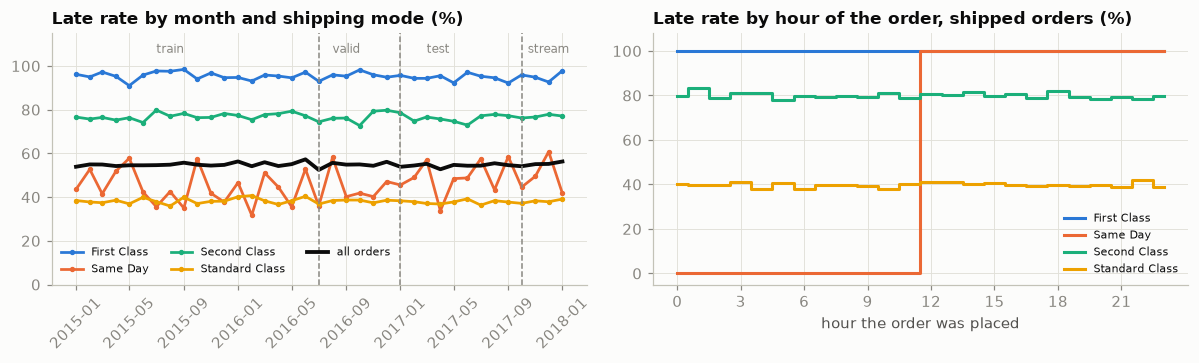

In [5]:
month = orders.placed.dt.to_period("M")
hour = orders.placed.dt.hour
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
ax = axes[0]
mon = pd.DataFrame({"m": month, "y": y, "mode": orders["mode"]}).groupby(["m", "mode"], observed=True).y.mean().unstack()
for md in MODES:
    ax.plot(mon.index.to_timestamp(), mon[md] * 100, "-o", ms=2.5, lw=1.8, color=MCOL[md], label=md)
ax.plot(mon.index.to_timestamp(), pd.DataFrame({"m": month, "y": y}).groupby("m").y.mean() * 100, "-", lw=2.5, color=INK, label="all orders")
for x in [TRAIN_END, VALID_END, TEST_END]:
    ax.axvline(x, color=MUTED, ls="--", lw=1)
for x, lab_ in [("2015-07-01", "train"), ("2016-08-01", "valid"), ("2017-03-01", "test"), ("2017-10-15", "stream")]:
    ax.text(pd.Timestamp(x), 106, lab_, color=MUTED, fontsize=8)
ax.set_ylim(0, 115); ax.set_title("Late rate by month and shipping mode (%)"); ax.legend(fontsize=7, ncol=3, loc="lower left")
ax.tick_params(axis="x", rotation=45)
ax = axes[1]
hr = pd.DataFrame({"h": hour, "y": y, "mode": orders["mode"]})[shipped_ok].groupby(["h", "mode"], observed=True).y.mean().unstack()
for md in MODES:
    ax.step(hr.index, hr[md] * 100, where="mid", lw=2, color=MCOL[md], label=md)
ax.set_xticks(range(0, 24, 3)); ax.set_xlabel("hour the order was placed"); ax.set_ylim(-5, 108)
ax.set_title("Late rate by hour of the order, shipped orders (%)"); ax.legend(fontsize=7, loc="lower right")
plt.tight_layout()
gaps = orders.placed.diff().dt.total_seconds().div(60)
sd = shipped_ok & (orders["mode"] == "Same Day")
print(f"Same Day, shipped: late {y[sd & (hour < 12)].mean():.0%} of {int((sd & (hour < 12)).sum()):,} orders placed before noon, "
      f"{y[sd & (hour >= 12)].mean():.0%} of {int((sd & (hour >= 12)).sum()):,} after noon")
print(f"minutes between consecutive orders: {gaps.mode().iat[0]:.0f} for {(gaps == gaps.mode().iat[0]).mean():.0%} of orders · "
      f"late rate by year: " + " · ".join(f"{k} {v:.1%}" for k, v in y.groupby(orders.placed.dt.year).mean().items()))

Three facts decide everything that follows.

- **First Class is late by design.** It promises dispatch in 1 day; all 9,602 shipped First Class orders took exactly 2.
- **Same Day has a noon cut-off:** 0 % late before noon, 100 % after. Deterministic, but a legitimate feature: the hour is known at placement.
- **Second and Standard Class roll a five-sided die.** Dispatch takes 2 to 6 days, 20 % each; against promises of 2 and 4 days that is 80 % and 40 % late.

The late rate is flat (54.7 % in 2015, 55.1 % in 2016, 54.5 % in 2017): no trend, only a mix of services.

# Part B — The given model

*Sections 3–5: read them, then package the code unchanged and reproduce its numbers (C2). You do not change the method.*

## 3 · The model at order placement

*Part B · Given model · package `build_features`, `customer_history`, `fit`, `daily_queue`, `evaluate` and `rule_score` unchanged and reproduce the numbers (C2).*

The rule for every feature: **known when the customer presses *Place order***, when `POST /risk` is called. The provider never says when a column is written, so each is argued below, in a dictionary task C1's test can read.

In [6]:
AS_OF = {   # raw column → verdict at the moment the order is placed (the test in task C1 reads this dict)
    "shipping mode": "yes — used", "days for shipment (scheduled)": "yes — used (the promise)",
    "order date (dateorders)": "yes — hour and weekday", "order item quantity": "yes — units",
    "order item total": "yes — summed to the order value (it is per line)", "order item discount rate": "yes — discount",
    "category name": "yes — main line's category", "department name": "yes — main line's department",
    "market": "yes — used", "order region": "yes — used", "order country": "yes — top 40, else 'other'",
    "customer segment": "yes — used", "customer id": "yes — pseudonymised, as-of history only",
    "order city": f"not used — {lines.city.nunique():,} values", "order state": f"not used — {lines.state.nunique():,} values",
    "order item profit ratio": "doubtful — profit after costs; tested in Trap 1", "order profit per order": "doubtful — as above (per line)",
    "benefit per order": "duplicate of order profit per order", "sales per customer": "duplicate of order item total",
    "days for shipping (real)": "no — known at shipment ⚠", "shipping date (dateorders)": "no — known at shipment ⚠",
    "delivery status": "no — the outcome ⚠", "late_delivery_risk": "no — the label",
    "order status": "no — status when the extract was taken ⚠", "type": "no — a recoding of the status (Trap 2) ⚠",
}
audit = pd.DataFrame({"provider's description": desc.reindex(list(AS_OF)).str.slice(0, 70).values, "known at placement?": list(AS_OF.values())},
                     index=list(AS_OF))
display(audit)

,provider's description,known at placement?
shipping mode,The following shipping modes are presented : Standard Cl...,yes — used
days for shipment (scheduled),Days of scheduled delivery of the purchased product,yes — used (the promise)
order date (dateorders),Date on which the order is made,yes — hour and weekday
order item quantity,Number of products per order,yes — units
order item total,Total amount per order,yes — summed to the order value (it is per line)
order item discount rate,Order item discount percentage,yes — discount
category name,Description of the product category,yes — main line's category
department name,Department name of store,yes — main line's department
market,"Market to where the order is delivered : Africa , Europe...",yes — used
order region,Region of the world where the order is delivered : Sout...,yes — used


Four feature families: the **order** (mode, promise, hour, weekday, lines, units, value, discount, segment), the **product** (the main line's category and department), the **route** (market, region, country) and the **customer's history**: prior orders and their late rate, counting only orders placed at least `LABEL_MATURITY_DAYS` (7) earlier, because an outcome exists only once the order has shipped. Label maturity in miniature.

Three baselines frame the model: a random queue, the shift lead's rule of thumb (each mode's training late rate), and the same rule split at noon. Metrics: **AUPRC** against a 54 % base rate, and the **precision and recall of a daily queue of 15 orders**, what the operations director buys. Ties are broken at random for every score.

In [7]:
tr = orders.placed < TRAIN_END
va = (orders.placed >= TRAIN_END) & (orders.placed < VALID_END)
te = (orders.placed >= VALID_END) & (orders.placed < TEST_END)
st = orders.placed >= TEST_END
TOP_COUNTRIES = orders.loc[tr, "country"].value_counts().index[:40]          # chosen on the training window only

def customer_history(orders: pd.DataFrame, label: pd.Series, lag_days: int = LABEL_MATURITY_DAYS) -> pd.DataFrame:
    """Prior orders and late rate of the customer, counting only orders whose outcome was known `lag_days` before."""
    hist = pd.DataFrame({"customer": orders.customer, "t": orders.placed, "late": label.values}).sort_values("t")
    hist["n_cum"] = hist.groupby("customer").cumcount() + 1
    hist["late_cum"] = hist.groupby("customer").late.cumsum()
    q = pd.DataFrame({"customer": orders.customer, "cutoff": orders.placed - pd.Timedelta(days=lag_days),
                      "row": np.arange(len(orders))}).sort_values("cutoff")
    m = pd.merge_asof(q, hist[["customer", "t", "n_cum", "late_cum"]], left_on="cutoff", right_on="t", by="customer",
                      direction="backward", allow_exact_matches=True).sort_values("row")
    n = m.n_cum.fillna(0).values
    return pd.DataFrame({"cust_prior_orders": n, "cust_prior_late_rate": np.where(n > 0, m.late_cum.values / np.maximum(n, 1), np.nan)},
                        index=orders.index)

def build_features(orders: pd.DataFrame) -> pd.DataFrame:
    X = pd.DataFrame(index=orders.index)
    X["mode"] = orders["mode"]
    X["promise_days"] = orders.promise_days
    X["hour"] = orders.placed.dt.hour
    X["dow"] = orders.placed.dt.day_of_week
    X["n_lines"], X["units"], X["value"] = orders.n_lines, orders.units, orders.value
    X["discount_rate"] = 1 - orders.value / orders.list_value
    X["segment"] = orders.segment
    X["main_category"], X["main_dept"] = orders.main_category, orders.main_dept
    X["market"], X["region"] = orders.market, orders.region
    X["country"] = pd.Categorical(orders.country.astype(str).where(orders.country.isin(TOP_COUNTRIES), "other"))
    return X.join(customer_history(orders, y))

X = build_features(orders)
ORDER = ["mode", "promise_days", "hour", "dow", "n_lines", "units", "value", "discount_rate", "segment"]
PRODUCT = ["main_category", "main_dept"]
GEO = ["market", "region", "country"]
HISTORY = ["cust_prior_orders", "cust_prior_late_rate"]
HONEST = ORDER + PRODUCT + GEO + HISTORY
LGB_PARAMS = dict(n_estimators=300, learning_rate=0.05, num_leaves=31, min_child_samples=50, subsample=0.8,
                  subsample_freq=1, colsample_bytree=0.8, reg_lambda=1.0, random_state=SEED, verbose=-1, n_jobs=N_JOBS)

def fit(cols, train=tr, X_=None, y_=None):
    X_ = X if X_ is None else X_
    y_ = y if y_ is None else y_
    return lgb.LGBMClassifier(**LGB_PARAMS).fit(X_.loc[train, cols], y_[train])

def untie(score):
    """Equal scores are broken at random, never by row order (scikit-learn scores a tied block pessimistically)."""
    return np.asarray(score, float) + np.random.default_rng(SEED).random(len(score)) * 1e-9

def daily_queue(score, days, k=EXPEDITE_PER_DAY):
    """Each day, expedite the k highest-scoring orders."""
    rank = pd.Series(untie(score)).groupby(np.asarray(days)).rank(ascending=False, method="first").values
    return rank <= k

def evaluate(score, mask, name, k=EXPEDITE_PER_DAY, y_=None):
    yv, sv = (y if y_ is None else y_)[mask].values, untie(score)
    q = daily_queue(sv, day[mask].values, k)
    return {"model": name, "AUPRC": average_precision_score(yv, sv), "ROC-AUC": roc_auc_score(yv, sv),
            "precision@capacity": yv[q].mean(), "recall@capacity": yv[q].sum() / yv.sum()}

def rule_score(keys, train=tr):
    """A lookup table: the training late rate for each combination of `keys`."""
    k = keys.astype(str).agg(" | ".join, axis=1)
    rates = y[train].groupby(k[train]).mean()
    return k.map(rates).fillna(y[train].mean()).values

for name, m_ in [("train", tr), ("valid", va), ("test", te), ("stream", st)]:
    print(f"{name:6s} {m_.sum():6,} orders · {orders.loc[m_, 'placed'].min():%b %Y} – {orders.loc[m_, 'placed'].max():%b %Y} · "
          f"late {y[m_].mean():.1%} · {orders[m_].groupby(day[m_]).size().mean():.1f} orders a day")

s_mode = rule_score(orders[["mode"]])
s_noon = rule_score(pd.DataFrame({"mode": orders["mode"], "pm": (orders.placed.dt.hour >= 12)}))
t0 = time.time()
m_honest = fit(HONEST)
p_honest = m_honest.predict_proba(X[HONEST])[:, 1]
NO_RULE = [c for c in HONEST if c not in ("mode", "promise_days", "hour")]
m_norule = fit(NO_RULE)
p_norule = m_norule.predict_proba(X[NO_RULE])[:, 1]
rand_score = np.random.default_rng(SEED).random(len(orders))
HONEST_NAME, NOON_NAME, NORULE_NAME = ("LightGBM: everything known at placement", "rule: by mode and before/after noon",
                                       "LightGBM: without mode, promise and hour")
results = pd.DataFrame([evaluate(rand_score[te.values], te, "random queue"),
                        evaluate(s_mode[te.values], te, "rule: late rate by shipping mode"),
                        evaluate(s_noon[te.values], te, NOON_NAME),
                        evaluate(p_honest[te.values], te, HONEST_NAME),
                        evaluate(p_norule[te.values], te, NORULE_NAME)]).set_index("model")
oracle = y[te].groupby(day[te]).apply(lambda s: min(s.sum(), EXPEDITE_PER_DAY)).sum() / y[te].sum()
print(f"fitted in {time.time()-t0:.0f}s · test Jan – Sep 2017, base rate {y[te].mean():.1%} · "
      f"capacity {EXPEDITE_PER_DAY} a day; a perfect queue would reach recall {oracle:.1%}")
show(results, {"AUPRC": "{:.3f}", "ROC-AUC": "{:.3f}", "precision@capacity": "{:.1%}", "recall@capacity": "{:.1%}"})

train  31,249 orders · Jan 2015 – Jun 2016 · late 55.0% · 57.1 orders a day
valid  10,514 orders · Jul 2016 – Dec 2016 · late 54.7% · 57.1 orders a day
test   15,586 orders · Jan 2017 – Sep 2017 · late 54.4% · 57.1 orders a day
stream  8,403 orders · Oct 2017 – Jan 2018 · late 55.2% · 68.3 orders a day


fitted in 6s · test Jan – Sep 2017, base rate 54.4% · capacity 15 a day; a perfect queue would reach recall 48.3%


,AUPRC,ROC-AUC,precision@capacity,recall@capacity
model,,,,
random queue,0.541,0.495,53.3%,25.7%
rule: late rate by shipping mode,0.789,0.722,84.5%,40.8%
rule: by mode and before/after noon,0.809,0.754,87.2%,42.1%
LightGBM: everything known at placement,0.812,0.758,86.8%,41.9%
"LightGBM: without mode, promise and hour",0.544,0.500,53.5%,25.8%


share of LightGBM's split gain in mode, promise and hour: 68%; the other 13 features: 32%
honest model's score by mode and half-day (test):


,mean score,std,orders
First Class · am,0.956,0.020,"1,248"
First Class · pm,0.960,0.015,"1,116"
Same Day · am,0.073,0.017,403
Same Day · pm,0.886,0.026,453
Second Class · am,0.774,0.050,"1,486"
Second Class · pm,0.774,0.054,"1,526"
Standard Class · am,0.379,0.064,"4,665"
Standard Class · pm,0.393,0.063,"4,689"


model − rule, 95 % day-bootstrap interval (200 resamples): AUPRC [-0.002, +0.009] · recall@capacity [-0.005, +0.001]
CI gate on the frozen holdout (15,586 orders, Jan – Sep 2017, SHA-256 a5a5aa2d5bed717a…): recall@capacity 0.419 ≥ 0.4 → PASS · AUPRC 0.812 ≥ rule 0.809 − 0.01 → PASS


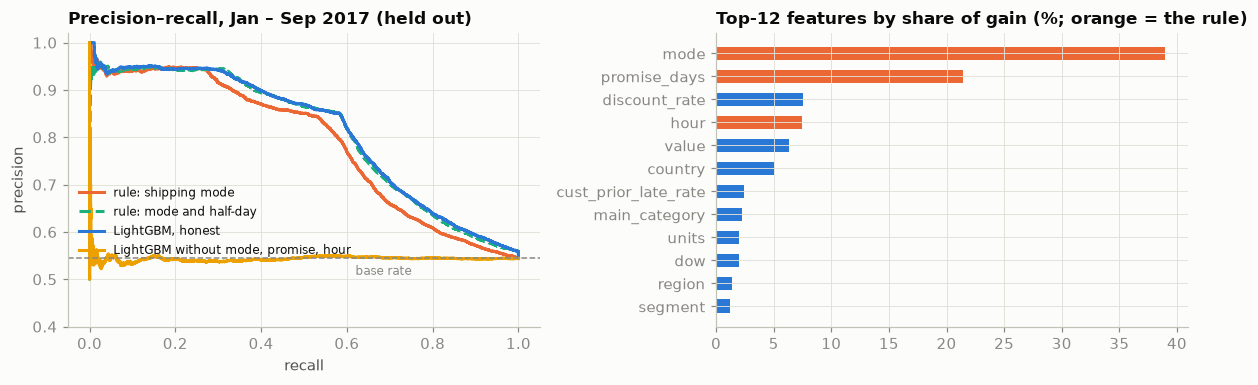

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
ax = axes[0]
yte = y[te].values
for s, lab_, color, ls in [(s_mode[te.values], "rule: shipping mode", SERIES[1], "-"), (s_noon[te.values], "rule: mode and half-day", SERIES[2], "--"),
                           (p_honest[te.values], "LightGBM, honest", SERIES[0], "-"), (p_norule[te.values], "LightGBM without mode, promise, hour", SERIES[3], "-")]:
    pr, rc, _ = precision_recall_curve(yte, untie(s))
    ax.plot(rc, pr, lw=2, color=color, label=lab_, ls=ls)
ax.axhline(yte.mean(), color=MUTED, ls="--", lw=1); ax.text(0.62, yte.mean() - 0.035, "base rate", color=MUTED, fontsize=8)
ax.set_ylim(0.4, 1.02); ax.set_title("Precision–recall, Jan – Sep 2017 (held out)"); ax.set_xlabel("recall"); ax.set_ylabel("precision")
ax.legend(fontsize=8, loc="lower left", bbox_to_anchor=(0.0, 0.2))
ax = axes[1]
imp = pd.Series(m_honest.booster_.feature_importance("gain"), index=HONEST)
imp = (imp / imp.sum()).sort_values(ascending=False)
RULE_SHARE = imp[["mode", "promise_days", "hour"]].sum()
imp = imp.head(12)
ax.barh(imp.index[::-1], imp.values[::-1] * 100, color=[SERIES[1] if f in ("mode", "promise_days", "hour") else SERIES[0] for f in imp.index[::-1]], height=0.6)
ax.set_title("Top-12 features by share of gain (%; orange = the rule)")
plt.tight_layout()
levels = pd.Series(p_honest[te.values]).groupby(orders.loc[te, "mode"].astype(str).values + np.where(orders.loc[te, "placed"].dt.hour.values >= 12, " · pm", " · am")).agg(["mean", "std", "size"])
print(f"share of LightGBM's split gain in mode, promise and hour: {RULE_SHARE:.0%}; the other {len(HONEST) - 3} features: {1 - RULE_SHARE:.0%}")
print("honest model's score by mode and half-day (test):")
show(levels.rename(columns={"mean": "mean score", "std": "std", "size": "orders"}), {"mean score": "{:.3f}", "std": "{:.3f}", "orders": "{:,}"})
holdout = pd.concat([X.loc[te, HONEST], y[te], day[te]], axis=1)
fingerprint = hashlib.sha256(pd.util.hash_pandas_object(holdout, index=True).values.tobytes()).hexdigest()
# how far apart are model and rule, given only 273 test days? resample whole days (each day's queue stays intact)
d_te = day[te].values
by_day = [np.flatnonzero(d_te == d) for d in np.unique(d_te)]
s_m, s_r = untie(p_honest[te.values]), untie(s_noon[te.values])
q_m, q_r = daily_queue(s_m, d_te), daily_queue(s_r, d_te)
rng = np.random.default_rng(SEED)
boot = []
for _ in range(N_BOOT):
    ii = np.concatenate([by_day[j] for j in rng.integers(0, len(by_day), len(by_day))])
    yy = yte[ii]
    boot.append((average_precision_score(yy, s_m[ii]) - average_precision_score(yy, s_r[ii]),
                 (yy[q_m[ii]].sum() - yy[q_r[ii]].sum()) / yy.sum()))
(a_lo, r_lo), (a_hi, r_hi) = np.percentile(boot, [2.5, 97.5], axis=0)
r_, rule_auprc = results.loc[HONEST_NAME], results.loc[NOON_NAME, "AUPRC"]
print(f"model − rule, 95 % day-bootstrap interval ({N_BOOT} resamples): AUPRC [{a_lo:+.3f}, {a_hi:+.3f}] · recall@capacity [{r_lo:+.3f}, {r_hi:+.3f}]")
print(f"CI gate on the frozen holdout ({te.sum():,} orders, Jan – Sep 2017, SHA-256 {fingerprint[:16]}…): "
      f"recall@capacity {r_['recall@capacity']:.3f} ≥ {GATE_MIN_RECALL} → {'PASS' if r_['recall@capacity'] >= GATE_MIN_RECALL else 'FAIL'} · "
      f"AUPRC {r_['AUPRC']:.3f} ≥ rule {rule_auprc:.3f} − {GATE_AUPRC_MARGIN} → "
      f"{'PASS' if r_['AUPRC'] >= rule_auprc - GATE_AUPRC_MARGIN else 'FAIL'}")

**The model has learned the generator, and nothing else.** LightGBM reaches AUPRC 0.812 and catches 41.9 % of late orders with 15 expedites a day (86.8 % of expedites were late). The rule *by mode and half-day* scores 0.809 and 42.1 %: the same queue. Without mode, promise and hour, LightGBM is a random queue (0.544 against 0.541). The score has five levels (First Class 0.96 down to Same Day morning 0.07) plus noise that picks which Second Class orders fill the last places. A perfect queue would catch 48.3 %; the gap is the die. Split gain still credits the other features with 32 %: gain measures use, not value.

**The CI gate is non-inferiority.** Model and rule are the same queue, so "beat the rule" would pass or fail on noise: the day-bootstrap 95 % interval of the difference is −0.002 to +0.009 AUPRC and −0.005 to +0.001 recall. The gate asks for recall at capacity ≥ 0.40 and AUPRC at most `GATE_AUPRC_MARGIN` (0.01) below the rule; the baseline passes.

## 4 · The operating point: fifteen expedites a day, or a new promise

*Part B · Given model · package `policy_row`; C3 asks you to own the capacity, the costs and the promise.*

Capacity is the constraint, so the operating point is a **daily queue**: each day, expedite the 15 highest-scoring orders. Two costs, both assumptions for task C3: an expedite costs `EXPEDITE_COST_EUR` (€6); a late order reaching the customer costs `LATE_COST_EUR` (€20). We assume an expedited order ships on time, the most generous reading.

The other lever is the promise. The simulation re-quotes each mode at the 75th percentile of its training dispatch days, assuming dispatch times do not change with the promise.

threshold chosen on validation (most alerts ≤ 15/day): 0.799 → test: 13.9 alerts a day, 35% of days over capacity, capacity used 82%
  the next threshold down (0.798) would raise 15.1 alerts a day on validation


new promises (days): First Class 1 → 2 · Same Day 0 → 1 · Second Class 2 → 5 · Standard Class 4 → 5


,late orders a day (before),expedited a day,late caught,precision of expedites,late a day reaching customers,cost a day €
policy,,,,,,
today's promises · no expediting,31.1,0.0,0.0%,0.0%,31.1,€622
today's promises · random queue,31.1,15.0,25.7%,53.3%,23.1,€552
today's promises · rule queue (mode),31.1,15.0,40.8%,84.5%,18.4,€458
today's promises · model queue,31.1,15.0,41.9%,86.8%,18.1,€451
promise at P75 · no expediting,8.6,0.0,0.0%,0.0%,8.6,€172
promise at P75 · rule queue,8.6,15.0,31.8%,18.2%,5.9,€207


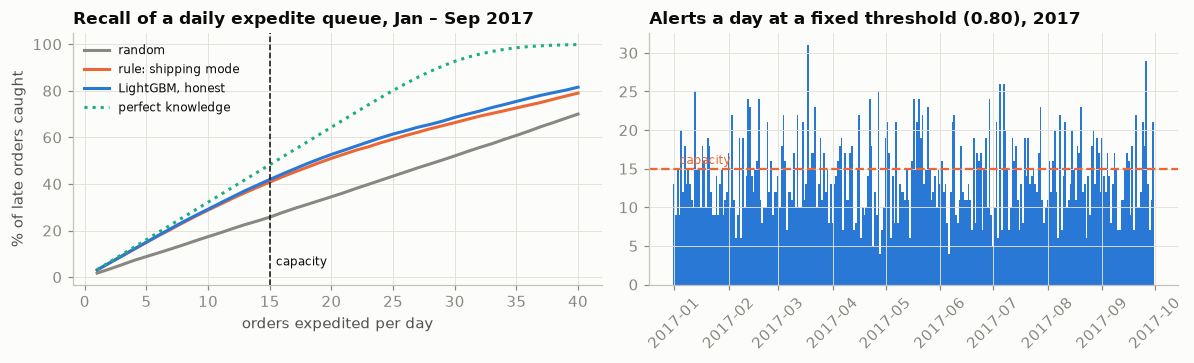

In [9]:
ks = np.arange(1, 41)
curves = {}
for name, s in [("random", rand_score), ("rule: shipping mode", s_mode), ("LightGBM, honest", p_honest)]:
    curves[name] = [y[te].values[daily_queue(s[te.values], day[te].values, k)].sum() / y[te].sum() for k in ks]
late_per_day = y[te].groupby(day[te]).sum()
curves["perfect knowledge"] = [np.minimum(late_per_day, k).sum() / late_per_day.sum() for k in ks]

# threshold on validation vs a daily queue
p_va = p_honest[va.values]
cand = np.unique(np.round(p_va, 3))
alerts_va = np.array([(p_va >= c).sum() / day[va].nunique() for c in cand])
THR = float(cand[alerts_va <= EXPEDITE_PER_DAY].min())
alerts_te = pd.Series(p_honest[te.values] >= THR).groupby(day[te].values).sum()
print(f"threshold chosen on validation (most alerts ≤ {EXPEDITE_PER_DAY}/day): {THR:.3f} → test: {alerts_te.mean():.1f} alerts a day, "
      f"{(alerts_te > EXPEDITE_PER_DAY).mean():.0%} of days over capacity, capacity used {alerts_te.clip(upper=EXPEDITE_PER_DAY).sum() / (EXPEDITE_PER_DAY * len(alerts_te)):.0%}")
print(f"  the next threshold down ({cand[cand < THR].max():.3f}) would raise {(p_va >= cand[cand < THR].max()).sum() / day[va].nunique():.1f} alerts a day on validation")

# the promise: re-quote each mode at the PROMISE_QUANTILE of training dispatch days (shipped orders only)
ship_tr = tr & shipped_ok
cdf = pd.crosstab(orders.loc[ship_tr, "mode"].astype(str), outcome.real_days[ship_tr], normalize="index").cumsum(axis=1)
NEW_PROMISE = (cdf >= PROMISE_QUANTILE - 1e-9).idxmax(axis=1)                    # smallest d with P(days ≤ d) ≥ quantile
new_promise = orders["mode"].astype(str).map(NEW_PROMISE)
y_requote = ((outcome.real_days > new_promise) & shipped_ok).astype(int)   # assumes dispatch times do not change with the promise
s_requote = orders["mode"].astype(str).map(y_requote[tr].groupby(orders.loc[tr, "mode"].astype(str)).mean()).values

def policy_row(name, late_label, queue):
    yl = late_label[te].values
    n_days = day[te].nunique()
    caught = (queue & (yl == 1)).sum()
    late_left = yl.sum() - caught
    return {"policy": name, "late orders a day (before)": yl.sum() / n_days, "expedited a day": queue.sum() / n_days,
            "late caught": caught / max(yl.sum(), 1), "precision of expedites": caught / max(queue.sum(), 1),
            "late a day reaching customers": late_left / n_days,
            "cost a day €": (LATE_COST_EUR * late_left + EXPEDITE_COST_EUR * queue.sum()) / n_days}

none_q = np.zeros(te.sum(), bool)
pol = pd.DataFrame([
    policy_row("today's promises · no expediting", y, none_q),
    policy_row("today's promises · random queue", y, daily_queue(rand_score[te.values], day[te].values)),
    policy_row("today's promises · rule queue (mode)", y, daily_queue(s_mode[te.values], day[te].values)),
    policy_row("today's promises · model queue", y, daily_queue(p_honest[te.values], day[te].values)),
    policy_row(f"promise at P{int(PROMISE_QUANTILE*100)} · no expediting", y_requote, none_q),
    policy_row(f"promise at P{int(PROMISE_QUANTILE*100)} · rule queue", y_requote, daily_queue(s_requote[te.values], day[te].values)),
]).set_index("policy")
print("new promises (days): " + " · ".join(f"{m} {orders.loc[orders['mode'] == m, 'promise_days'].iat[0]} → {NEW_PROMISE[m]}" for m in MODES))
show(pol, {"late orders a day (before)": "{:.1f}", "expedited a day": "{:.1f}", "late caught": "{:.1%}",
           "precision of expedites": "{:.1%}", "late a day reaching customers": "{:.1f}", "cost a day €": "€{:,.0f}"})

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
ax = axes[0]
for (name, c), color in zip(curves.items(), [MUTED, SERIES[1], SERIES[0], SERIES[2]]):
    ax.plot(ks, np.array(c) * 100, lw=2, color=color, label=name, ls=":" if name == "perfect knowledge" else "-")
ax.axvline(EXPEDITE_PER_DAY, color=INK, ls="--", lw=1); ax.text(EXPEDITE_PER_DAY + 0.5, 5, "capacity", fontsize=8)
ax.set_xlabel("orders expedited per day"); ax.set_ylabel("% of late orders caught")
ax.set_title("Recall of a daily expedite queue, Jan – Sep 2017"); ax.legend(fontsize=8)
ax = axes[1]
ax.bar(alerts_te.index, alerts_te.values, width=1, color=SERIES[0])
ax.axhline(EXPEDITE_PER_DAY, color=SERIES[1], lw=1.5, ls="--"); ax.text(alerts_te.index[3], EXPEDITE_PER_DAY + 0.6, "capacity", color=SERIES[1], fontsize=8)
ax.set_title(f"Alerts a day at a fixed threshold ({THR:.2f}), 2017"); ax.tick_params(axis="x", rotation=45)
plt.tight_layout()

Read the policy table from the bottom.

- **The promise beats the model.** Promising 2 days for First Class, 1 for Same Day and 5 for the others removes 72 % of broken promises (31.1 → 8.6 a day) without an expedite: €172 a day against €451 for the best queue.
- **An honest promise makes expediting unprofitable:** only 18.2 % of the queue would be late, so each expedite spends €6 to save €3.64 (€207 a day against €172).
- **With today's promises, ranking pays.** No queue costs €622 a day, a random one €552; the rule (€458) and the model (€451) are €7 apart.

The decision is an ADR on the promises, priced against the sales a slower promise loses (not in this data).

**A threshold cannot hit a capacity on a stepped score.** The lowest threshold that stays within 15 a day on validation (0.80) gives 13.9 alerts a day in 2017, 35 % of days over capacity, 82 % of capacity used. Rank each day's orders and cut at k.

## 5 · The traps ⚠

*Part B · Given model · read; C1 turns each trap into a test (`scores_with` shows the leaks).*

Six shortcuts, each a better number and a worse decision, measured naive against honest.

**Trap 1 — columns written at shipment.** Real days, the shipping date and `Delivery Status` are written when the order leaves the warehouse, when the label is decided. Each, added to the honest set:

In [10]:
def scores_with(extra: dict, base=HONEST):
    """Add columns to a feature set, refit on the training months, score the test months."""
    Xe = X.copy()
    for k_, v in extra.items():
        Xe[k_] = v
    cols = base + list(extra)
    return fit(cols, X_=Xe).predict_proba(Xe.loc[te, cols])[:, 1]

AFTER = {
    "real_days": outcome.real_days,
    "delivery_status": outcome.delivery_status,
    "days_to_ship": (outcome.shipped - orders.placed).dt.total_seconds() / 86400,
    "profit_ratio": orders.profit / orders.value,
    "status": outcome.status,
    "pay_type": outcome.pay_type,
}
rows = [evaluate(p_honest[te.values], te, "honest baseline")]
for name, col in AFTER.items():
    rows.append(evaluate(scores_with({name: col}), te, f"+ {name}" + (" ⚠" if name != "profit_ratio" else "")))
trap1 = pd.DataFrame(rows).set_index("model")
show(trap1, {"AUPRC": "{:.3f}", "ROC-AUC": "{:.3f}", "precision@capacity": "{:.1%}", "recall@capacity": "{:.1%}"})

,AUPRC,ROC-AUC,precision@capacity,recall@capacity
model,,,,
honest baseline,0.812,0.758,86.8%,41.9%
+ real_days ⚠,0.954,0.971,95.6%,46.1%
+ delivery_status ⚠,1.000,1.000,100.0%,48.3%
+ days_to_ship ⚠,0.954,0.971,95.3%,46.0%
+ profit_ratio,0.810,0.756,86.9%,41.9%
+ status ⚠,0.854,0.796,90.8%,43.8%
+ pay_type ⚠,0.829,0.764,88.3%,42.6%


`Delivery Status` *is* the label (AUPRC 1.000); real days or the shipping date give 0.954, short of 1.000 only because cancelled orders carry dispatch days too. The profit ratio, perhaps booked after shipping costs, changes nothing (0.810): doubtful columns are tested, not assumed. The fix: the outcome frame of Section 1, plus a test.

**Trap 2 — the status and its shadow, `Type`.** `Order Status` is the status when the extract was taken. Cross it with the payment type:

In [11]:
st_tbl = pd.crosstab(outcome.status, outcome.pay_type)
st_tbl["late rate"] = y.groupby(outcome.status, observed=True).mean()
st_tbl["delivery status"] = outcome.groupby("status", observed=True).delivery_status.agg(lambda s: " / ".join(sorted(s.astype(str).unique())))
show(st_tbl, {c: "{:,}" for c in outcome.pay_type.cat.categories} | {"late rate": "{:.1%}"})

pay_type,CASH,DEBIT,PAYMENT,TRANSFER,late rate,delivery status
status,,,,,,
CANCELED,0,0,0,"1,367",0.0%,Shipping canceled
CLOSED,"7,249",0,0,0,56.7%,Advance shipping / Late delivery / Shipping on time
COMPLETE,0,"21,716",0,0,57.7%,Advance shipping / Late delivery / Shipping on time
ON_HOLD,0,"3,624",0,0,56.4%,Advance shipping / Late delivery / Shipping on time
PAYMENT_REVIEW,0,0,704,0,57.5%,Advance shipping / Late delivery / Shipping on time
PENDING,0,0,0,"7,321",57.6%,Advance shipping / Late delivery / Shipping on time
PENDING_PAYMENT,0,0,"14,382",0,57.4%,Advance shipping / Late delivery / Shipping on time
PROCESSING,0,0,0,"7,901",56.9%,Advance shipping / Late delivery / Shipping on time
SUSPECTED_FRAUD,0,0,0,"1,488",0.0%,Shipping canceled


Every `CANCELED` and `SUSPECTED_FRAUD` order is labelled *not late*; the other seven statuses are 56–58 % late: status says only whether the order ships. `Type` looks like a payment method, but each status maps to exactly one type, and every cancellation is a TRANSFER. Status lifts AUPRC to 0.854 and `Type` to 0.829 (Trap 1's table), both by recognising orders that will never ship.

**Trap 3 — the customer's late rate, and the random split.** Customers return (3.18 orders each), and their late rate is the obvious cousin of Task 02's velocity features:

In [12]:
cols_nh = [c for c in HONEST if c not in HISTORY]
p_all_orders = scores_with({"cust_late_rate_all": y.groupby(orders.customer).transform("mean")}, base=cols_nh)   # ⚠
p_train_months = scores_with({"cust_late_rate_train": orders.customer.map(y[tr].groupby(orders.customer[tr]).mean()).values}, base=cols_nh)
# the same model on lines: forward, then a random 70/30 split of lines (Jan 2015 – Sep 2017)
L = lines.loc[lines.placed < TEST_END, ["order_id", "placed"]].reset_index(drop=True)
row_of = pd.Series(np.arange(len(orders)), index=orders.order_id)
XL, yL = X.iloc[row_of.reindex(L.order_id).values].reset_index(drop=True), y.iloc[row_of.reindex(L.order_id).values].reset_index(drop=True)
ltr, lte = (L.placed < TRAIN_END).values, (L.placed >= VALID_END).values
p_lines_fwd = lgb.LGBMClassifier(**LGB_PARAMS).fit(XL.loc[ltr, HONEST], yL[ltr]).predict_proba(XL.loc[lte, HONEST])[:, 1]
i_tr, i_te = train_test_split(np.arange(len(L)), test_size=0.3, random_state=SEED, stratify=yL)
p_lines_rand = lgb.LGBMClassifier(**LGB_PARAMS).fit(XL.iloc[i_tr][HONEST], yL.iloc[i_tr]).predict_proba(XL.iloc[i_te][HONEST])[:, 1]
sibling = L.order_id.iloc[i_te].isin(set(L.order_id.iloc[i_tr])).mean()
trap3 = pd.DataFrame([
    {"unit": "orders", "split": "forward", "customer history": "as-of, matured orders only (honest)", "AUPRC": average_precision_score(yte, p_honest[te.values])},
    {"unit": "orders", "split": "forward", "customer history": "late rate over all the customer's orders ⚠", "AUPRC": average_precision_score(yte, p_all_orders)},
    {"unit": "orders", "split": "forward", "customer history": "late rate over the training months ⚠", "AUPRC": average_precision_score(yte, p_train_months)},
    {"unit": "lines", "split": "forward", "customer history": "as-of", "AUPRC": average_precision_score(yL[lte], p_lines_fwd)},
    {"unit": "lines", "split": "random 70/30 ⚠", "customer history": "as-of", "AUPRC": average_precision_score(yL.iloc[i_te], p_lines_rand)},
]).set_index(["unit", "split", "customer history"])
print(f"orders per customer: {orders.groupby('customer').size().mean():.2f} · random split of lines: {sibling:.1%} of test lines "
      f"have a sibling line of the same order in training (forward split: 0%)")
show(trap3, {"AUPRC": "{:.3f}"})

orders per customer: 3.18 · random split of lines: 86.5% of test lines have a sibling line of the same order in training (forward split: 0%)


AUPRC
unit   split          customer history                                 
orders forward        as-of, matured orders only (honest)         0.812
                      late rate over all the customer's orders ⚠  0.892
                      late rate over the training months ⚠        0.645
lines  forward        as-of                                       0.808
       random 70/30 ⚠ as-of                                       0.879

Over all the customer's orders, the rate contains the label (0.892). Over the training months, it contains each training row's own outcome; the model leans on it, and in 2017 it is noise (0.645). The as-of version is honest and worth nothing: the generator gives customers no habits. On lines, a random 70/30 split puts a sibling line of the same order in training for 86.5 % of test lines, and the model memorises the siblings (0.879 against 0.808 forward). Split by order, forward in time.

**Trap 4 — testing only the orders that shipped.** Cancelled orders "have no delivery", but at placement nobody knows which orders will be cancelled:

In [13]:
shipped_te = te & shipped_ok
r_all = evaluate(p_honest[te.values], te, "all orders placed (honest)")
r_ship = evaluate(p_honest[shipped_te.values], shipped_te, "only orders that shipped ⚠")
show(pd.DataFrame([r_all, r_ship]).set_index("model").assign(orders=[te.sum(), shipped_te.sum()]),
     {"AUPRC": "{:.3f}", "ROC-AUC": "{:.3f}", "precision@capacity": "{:.1%}", "recall@capacity": "{:.1%}", "orders": "{:,}"})

,AUPRC,ROC-AUC,precision@capacity,recall@capacity,orders
model,,,,,
all orders placed (honest),0.812,0.758,86.8%,41.9%,"15,586"
only orders that shipped ⚠,0.854,0.775,90.6%,43.8%,"14,904"


Filtering on a future fact adds 0.042 AUPRC (0.854 against 0.812) and makes the queue look 3.8 points more precise. Report on every order placed, and test that the evaluation frame keeps cancelled orders (task C1).

**Trap 5 — `SUSPECTED_FRAUD`: a second label, not a feature.**

In [14]:
fraud = (outcome.status == "SUSPECTED_FRAUD").astype(int)
transfer = outcome.pay_type == "TRANSFER"
hist_f = customer_history(orders, fraud)                                      # the customer's earlier flags, as-of
Xf = X[cols_nh].assign(cust_prior_fraud_rate=hist_f.cust_prior_late_rate)
pf = lgb.LGBMClassifier(**LGB_PARAMS).fit(Xf[tr], fraud[tr]).predict_proba(Xf[te])[:, 1]
prior = hist_f.cust_prior_late_rate
print(f"suspected fraud: {fraud.sum():,} orders ({fraud.mean():.2%}) · delivery status '{outcome.delivery_status[fraud == 1].unique()[0]}' "
      f"and late = {y[fraud == 1].max()} for every one · pay type TRANSFER for {transfer[fraud == 1].mean():.0%} "
      f"(fraud rate {fraud[transfer].mean():.1%} within TRANSFER, {fraud[~transfer].mean():.1%} elsewhere)")
print(f"fraud rate after an earlier flagged order {fraud[prior > 0].mean():.2%} · after unflagged orders only {fraud[prior == 0].mean():.2%}")
print(f"fraud model on order-time features, test: AUPRC {average_precision_score(fraud[te], pf):.3f} against a base rate of "
      f"{fraud[te].mean():.3f} · ROC-AUC {roc_auc_score(fraud[te], pf):.3f}")
r_ff = evaluate(scores_with({"suspected_fraud": fraud}), te, "")
print(f"suspected_fraud as a feature of the lateness model ⚠: AUPRC {r_ff['AUPRC']:.3f} against {results.loc[HONEST_NAME, 'AUPRC']:.3f}")

suspected fraud: 1,488 orders (2.26%) · delivery status 'Shipping canceled' and late = 0 for every one · pay type TRANSFER for 100% (fraud rate 8.2% within TRANSFER, 0.0% elsewhere)
fraud rate after an earlier flagged order 2.02% · after unflagged orders only 2.28%
fraud model on order-time features, test: AUPRC 0.023 against a base rate of 0.023 · ROC-AUC 0.499


suspected_fraud as a feature of the lateness model ⚠: AUPRC 0.833 against 0.812


As a feature it is Trap 2 again (0.833: fraud orders never ship). As its own question it belongs to payments risk, not the warehouse, and this data cannot answer it at order time: a forward fraud model scores AUPRC 0.023 against a base rate of 0.023, and an earlier flag does not raise the rate (2.02 % against 2.28 %). The only marker, TRANSFER, is the status itself. Treat the flag as a case for human review with its own ADR, never as an automatic action against a customer.

**Trap 6 — the generator: a rule plus a die.** When a model matches a two-line rule, suspect the data. Dispatch days by market:

In [15]:
sh_ = shipped_ok & orders["mode"].isin(["Second Class", "Standard Class"])
rd = pd.crosstab([orders.loc[sh_, "mode"].astype(str), orders.loc[sh_, "market"].astype(str)], outcome.real_days[sh_], normalize="index")
print("days from order to shipment, shipped Second and Standard Class orders, by market")
show(rd, {d: "{:.1%}" for d in rd.columns})
print(f"test AUPRC — LightGBM {results.loc[HONEST_NAME, 'AUPRC']:.3f} · rule by mode and half-day {results.loc[NOON_NAME, 'AUPRC']:.3f} · "
      f"LightGBM without mode, promise and hour {results.loc[NORULE_NAME, 'AUPRC']:.3f} · random {results.loc['random queue', 'AUPRC']:.3f}")

days from order to shipment, shipped Second and Standard Class orders, by market


real_days                        2      3      4      5      6
mode           market                                         
Second Class   Africa        19.6%  21.3%  19.0%  21.2%  19.0%
               Europe        19.8%  20.2%  19.3%  20.2%  20.5%
               LATAM         20.6%  19.2%  20.6%  19.4%  20.3%
               Pacific Asia  19.7%  19.4%  21.0%  20.6%  19.4%
               USCA          20.1%  20.1%  20.2%  19.1%  20.4%
Standard Class Africa        19.6%  20.0%  20.5%  19.9%  20.0%
               Europe        20.6%  20.1%  19.5%  19.6%  20.2%
               LATAM         20.2%  20.2%  20.3%  19.7%  19.7%
               Pacific Asia  20.2%  19.7%  19.8%  20.1%  20.3%
               USCA          19.8%  20.0%  20.2%  20.1%  19.9%

test AUPRC — LightGBM 0.812 · rule by mode and half-day 0.809 · LightGBM without mode, promise and hour 0.544 · random 0.541


Within Second and Standard Class each dispatch day takes 19–21 % of orders in every market; without mode and noon, AUPRC is 0.544, a random queue's 0.541. A "riskiest routes" dashboard would rank noise, and every difference you report must survive the question *could the generator have produced it?*

# Part C — Productionise it

*Sections 6–10: this is your assignment.*

## 6 · After deployment: the market moves, the risk does not

*Part C · Productionise · what your monitoring plan must catch; reuse `psi_cat` and `psi_num` (C5).*

Freeze the June 2016 model and run it to January 2018 on Task 02's two clocks: **now**, the inputs and the score (PSI against the training months); **later**, AUPRC and recall at capacity, once orders have shipped (within a week).

,orders a day,lines per order,late rate,AUPRC,recall@capacity,recall ceiling,unseen category,new customer,PSI market,PSI region,PSI mode,PSI main_category,PSI score
month,,,,,,,,,,,,,
2016-07,56.7,3.02,52.4%,0.807,43.1%,50.4%,0%,7%,8.15,7.22,0.00,0.02,0.10
2016-09,57.7,2.98,54.9%,0.819,41.3%,47.4%,0%,6%,6.71,11.57,0.00,0.01,0.08
2016-11,57.4,3.03,54.3%,0.812,40.4%,48.1%,0%,4%,6.35,11.47,0.00,0.02,0.03
2017-01,56.3,2.99,53.9%,0.811,43.3%,49.5%,0%,3%,2.33,6.88,0.00,0.02,0.03
2017-03,57.5,3.00,55.2%,0.818,41.4%,47.3%,0%,2%,6.60,5.72,0.00,0.01,0.02
2017-05,56.9,3.02,54.7%,0.816,42.1%,48.2%,4%,2%,6.60,5.73,0.00,0.35,0.02
2017-07,57.3,2.99,54.4%,0.829,41.9%,48.1%,4%,2%,6.72,5.83,0.00,0.31,0.03
2017-09,57.4,3.01,54.6%,0.802,41.9%,47.8%,8%,1%,6.72,5.82,0.00,0.57,0.04
2017-11,68.5,1.00,55.1%,0.815,35.2%,39.8%,100%,100%,3.71,3.23,0.00,14.18,0.21


stream Oct 2017 – Jan 2018: frozen model AUPRC 0.821 · retrained to Sep 2017 0.821 · rule by mode and half-day 0.821
Jul 2016 – Jan 2018, monthly: PSI market 2.33–8.15 · region 3.23–11.57 · mode max 0.006 · late rate 0.52–0.56 · AUPRC 0.80–0.84 · recall@capacity 0.40–0.43 before Oct 2017, 0.35–0.37 after · score PSI after Oct 2017 0.20–0.33 · category PSI after 10.71–14.23
stream: 99% single-line orders (training months 20%) · 99% of orders from customers with no earlier order · 68.3 orders a day


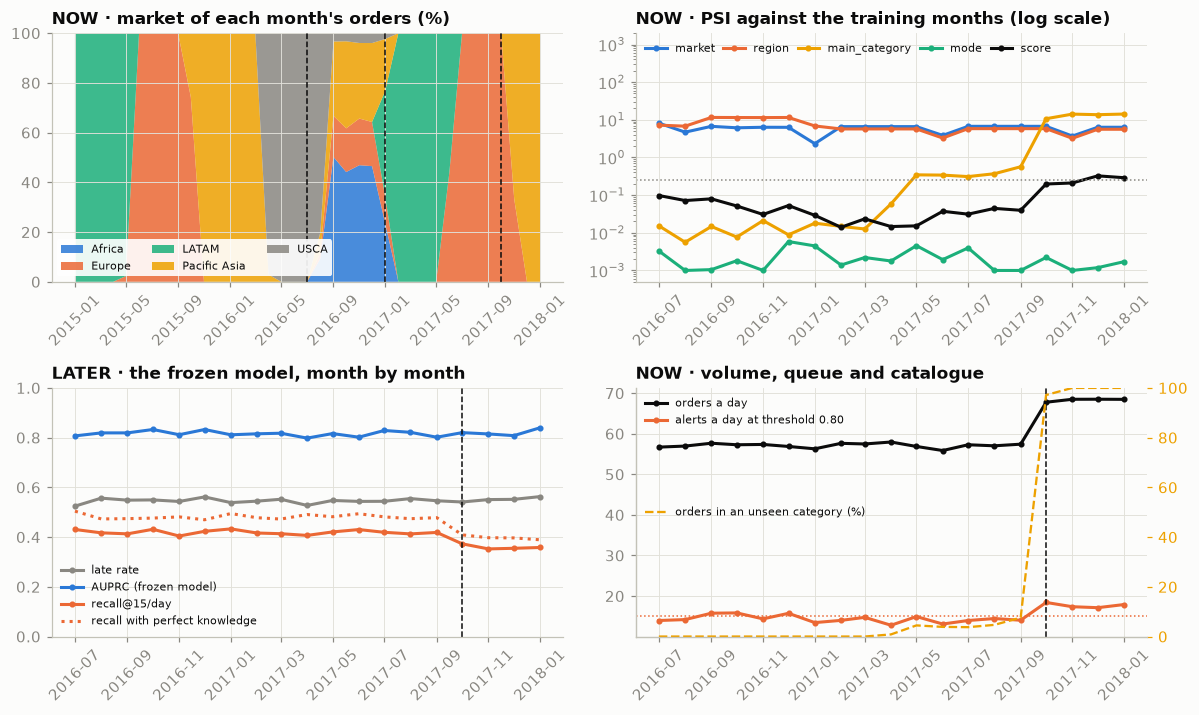

In [16]:
def psi_cat(ref, cur):
    r = ref.value_counts(normalize=True); c = cur.value_counts(normalize=True)
    idx_ = r.index.union(c.index)
    r, c = r.reindex(idx_, fill_value=0) + 1e-4, c.reindex(idx_, fill_value=0) + 1e-4
    return float(np.sum((c - r) * np.log(c / r)))

def psi_num(ref, cur, bins=10):
    edges = np.unique(np.quantile(ref, np.linspace(0, 1, bins + 1))); edges[0], edges[-1] = -np.inf, np.inf
    r = np.histogram(ref, edges)[0] / len(ref) + 1e-6
    c = np.histogram(cur, edges)[0] / len(cur) + 1e-6
    return float(np.sum((c - r) * np.log(c / r)))

after = ~tr
cats = {"market": orders.market.astype(str), "region": orders.region.astype(str), "mode": orders["mode"].astype(str),
        "main_category": orders.main_category.astype(str), "pm": (orders.placed.dt.hour >= 12).astype(str)}
seen_cat = set(orders.loc[tr, "main_category"].astype(str))
mrows = []
for mth in sorted(month[after].unique()):
    cur = (month == mth)
    d = day[cur]
    q = daily_queue(p_honest[cur.values], d.values)
    yv = y[cur].values
    row = {"month": mth, "orders a day": cur.sum() / d.nunique(), "lines per order": orders.n_lines[cur].mean(),
           "late rate": yv.mean(), "AUPRC": average_precision_score(yv, p_honest[cur.values]),
           "recall@capacity": yv[q].sum() / yv.sum(), "alerts a day (threshold)": (p_honest[cur.values] >= THR).sum() / d.nunique(),
           "recall ceiling": np.minimum(pd.Series(yv).groupby(d.values).sum(), EXPEDITE_PER_DAY).sum() / yv.sum(),
           "unseen category": (~orders.main_category[cur].astype(str).isin(seen_cat)).mean(),
           "new customer": (X.cust_prior_orders[cur] == 0).mean(), "PSI score": psi_num(p_honest[tr.values], p_honest[cur.values])}
    for k_, v in cats.items():
        row[f"PSI {k_}"] = psi_cat(v[tr], v[cur])
    mrows.append(row)
mon_tbl = pd.DataFrame(mrows).set_index("month")
mix = pd.crosstab(month, orders.market, normalize="index")

fig, axes = plt.subplots(2, 2, figsize=(11, 6.6))
ax = axes[0, 0]
mcol = dict(zip(mix.columns, SERIES + [MUTED]))
ax.stackplot(mix.index.to_timestamp(), (mix.T * 100).values, labels=mix.columns, colors=[mcol[c] for c in mix.columns], alpha=0.85)
for x in [TRAIN_END, VALID_END, TEST_END]:
    ax.axvline(x, color=INK, ls="--", lw=1)
ax.set_ylim(0, 100); ax.set_title("NOW · market of each month's orders (%)")
ax.legend(fontsize=7, ncol=3, loc="lower left", frameon=True, facecolor="white", edgecolor="none", framealpha=0.9)
ax.tick_params(axis="x", rotation=45)
ax = axes[0, 1]
t_ = mon_tbl.index.to_timestamp()
for c, color in [("PSI market", SERIES[0]), ("PSI region", SERIES[1]), ("PSI main_category", SERIES[3]), ("PSI mode", SERIES[2]), ("PSI score", INK)]:
    ax.plot(t_, mon_tbl[c].clip(lower=1e-3), "-o", ms=3, lw=2, color=color, label=c.replace("PSI ", ""))
ax.axhline(PSI_ALERT, color=MUTED, ls=":", lw=1); ax.set_yscale("log"); ax.set_ylim(5e-4, 2e3)
ax.set_title("NOW · PSI against the training months (log scale)"); ax.legend(fontsize=7, ncol=5, loc="upper left", columnspacing=0.8)
ax.tick_params(axis="x", rotation=45)
ax = axes[1, 0]
ax.plot(t_, mon_tbl["late rate"], "-o", ms=3, lw=2, color=MUTED, label="late rate")
ax.plot(t_, mon_tbl["AUPRC"], "-o", ms=3, lw=2, color=SERIES[0], label="AUPRC (frozen model)")
ax.plot(t_, mon_tbl["recall@capacity"], "-o", ms=3, lw=2, color=SERIES[1], label=f"recall@{EXPEDITE_PER_DAY}/day")
ax.plot(t_, mon_tbl["recall ceiling"], ":", lw=2, color=SERIES[1], label="recall with perfect knowledge")
ax.axvline(TEST_END, color=INK, ls="--", lw=1); ax.set_ylim(0, 1)
ax.set_title("LATER · the frozen model, month by month"); ax.legend(fontsize=7, loc="lower left"); ax.tick_params(axis="x", rotation=45)
ax = axes[1, 1]
ax.plot(t_, mon_tbl["orders a day"], "-o", ms=3, lw=2, color=INK, label="orders a day")
ax.plot(t_, mon_tbl["alerts a day (threshold)"], "-o", ms=3, lw=2, color=SERIES[1], label=f"alerts a day at threshold {THR:.2f}")
ax.axhline(EXPEDITE_PER_DAY, color=SERIES[1], ls=":", lw=1)
ax2 = ax.twinx(); ax2.plot(t_, mon_tbl["unseen category"] * 100, "--", lw=1.5, color=SERIES[3], label="orders in an unseen category (%)")
ax2.set_ylim(0, 100); ax2.grid(False); ax2.tick_params(colors=SERIES[3])
ax.axvline(TEST_END, color=INK, ls="--", lw=1)
ax.set_title("NOW · volume, queue and catalogue"); ax.legend(fontsize=7, loc="upper left"); ax2.legend(fontsize=7, loc="center left")
ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
cols_show = ["orders a day", "lines per order", "late rate", "AUPRC", "recall@capacity", "recall ceiling", "unseen category", "new customer",
             "PSI market", "PSI region", "PSI mode", "PSI main_category", "PSI score"]
show(mon_tbl.loc[mon_tbl.index[::2], cols_show], {"orders a day": "{:.1f}", "lines per order": "{:.2f}", "late rate": "{:.1%}", "AUPRC": "{:.3f}",
                                                  "recall@capacity": "{:.1%}", "recall ceiling": "{:.1%}", "unseen category": "{:.0%}", "new customer": "{:.0%}",
                                                  **{c: "{:.2f}" for c in cols_show if c.startswith("PSI")}})
m_re = fit(HONEST, train=~st)                      # retrained on everything to Sep 2017
p_re = m_re.predict_proba(X.loc[st, HONEST])[:, 1]
print(f"stream Oct 2017 – Jan 2018: frozen model AUPRC {average_precision_score(y[st], p_honest[st.values]):.3f} · "
      f"retrained to Sep 2017 {average_precision_score(y[st], p_re):.3f} · rule by mode and half-day {average_precision_score(y[st], untie(s_noon[st.values])):.3f}")
rng_ = lambda c, m=slice(None): f"{mon_tbl[c][m].min():.2f}–{mon_tbl[c][m].max():.2f}"
pre = mon_tbl.index < pd.Period(TEST_END, "M")
print(f"Jul 2016 – Jan 2018, monthly: PSI market {rng_('PSI market')} · region {rng_('PSI region')} · mode max {mon_tbl['PSI mode'].max():.3f} · "
      f"late rate {rng_('late rate')} · AUPRC {rng_('AUPRC')} · recall@capacity {rng_('recall@capacity', pre)} before Oct 2017, "
      f"{rng_('recall@capacity', ~pre)} after · score PSI after Oct 2017 {rng_('PSI score', ~pre)} · category PSI after {rng_('PSI main_category', ~pre)}")
print(f"stream: {orders.n_lines[st].eq(1).mean():.0%} single-line orders (training months {orders.n_lines[tr].eq(1).mean():.0%}) · "
      f"{(X.cust_prior_orders[st] == 0).mean():.0%} of orders from customers with no earlier order · "
      f"{st.sum() / day[st].nunique():.1f} orders a day")

The opposite of Task 02's silent failure: **loud drift, no damage.**

- **Market and region PSI is enormous every month** (market 2.3–8.2, region 3.2–11.6), while the late rate holds at 52–56 % and AUPRC at 0.80–0.84.
- **Shipping-mode PSI never exceeds 0.006**, and mode carries the risk. Weight drift alerts by what the model uses.
- **The October 2017 catalogue** sends category PSI to 10.7–14.2 and score PSI to 0.20–0.33. AUPRC does not move: 0.821 frozen, 0.821 retrained to September 2017, 0.821 for the rule.
- **Capacity is what changes.** Volume rises from 57 to 68.3 orders a day, so 15 expedites catch 35–37 % of late orders instead of 40–43 % (ceiling: 48 % → 39 %), and a fixed threshold overflows (bottom right). The operations director needs that alert; the model needs no retrain.

For the monitoring plan (task C5): score and mode-mix PSI as early warnings; recall at capacity backfilled weekly (labels mature within 7 days); queue length against capacity, daily; market and region PSI logged, not alerted.

## 7 · A small knowledge base: products, routes and promises

*Part C · Productionise · in Part C to keep the parts contiguous; package the KB, its shapes and `sparql` for E1's ablation and S1's context pack.*

The model needs little from a knowledge layer; the people around it need meaning. Competency questions (Session 07): *Which department sells this product? Which market serves this country? What do we promise for each mode, and what do we observe?* The answers form a small RDF graph, validated with SHACL (Session 08) and queried with SPARQL (Session 09); the clickstream is a second source for the product hierarchy.

In [17]:
DC = Namespace("https://ari3217.example/dataco#")
SH = Namespace("http://www.w3.org/ns/shacl#")
def node(kind, code):
    return DC[f"{kind}/{quote(str(code), safe='')}"]

kb = Graph(); kb.bind("dc", DC)
prod = lines.drop_duplicates("product_id")[["product_id", "product", "category_id", "category", "dept_id", "dept"]]
for r in prod.itertuples(index=False):
    p, c, d = node("product", r.product_id), node("category", r.category_id), node("department", r.dept_id)
    kb.add((p, RDF.type, DC.Product)); kb.add((p, DC.label, Literal(str(r.product)))); kb.add((p, DC.inCategory, c))
    kb.add((c, RDF.type, DC.Category)); kb.add((c, DC.label, Literal(str(r.category)))); kb.add((c, DC.inDepartment, d))
    kb.add((d, RDF.type, DC.Department)); kb.add((d, DC.label, Literal(str(r.dept))))
geo = lines.drop_duplicates(["country", "region"])[["country", "region", "market"]]
for r in geo.itertuples(index=False):
    co, re_, mk = node("country", r.country), node("region", r.region), node("market", r.market)
    kb.add((co, RDF.type, DC.Country)); kb.add((co, DC.label, Literal(str(r.country)))); kb.add((co, DC.inRegion, re_))
    kb.add((re_, RDF.type, DC.Region)); kb.add((re_, DC.label, Literal(str(r.region)))); kb.add((re_, DC.inMarket, mk))
    kb.add((mk, RDF.type, DC.Market)); kb.add((mk, DC.label, Literal(str(r.market))))
obs = outcome.real_days[ship_tr].groupby(orders.loc[ship_tr, "mode"].astype(str))
for md in MODES:
    n_ = node("mode", md)
    kb.add((n_, RDF.type, DC.ShippingMode)); kb.add((n_, DC.label, Literal(md)))
    kb.add((n_, DC.promisedDays, Literal(int(orders.loc[orders["mode"] == md, "promise_days"].iat[0]))))
    kb.add((n_, DC.observedMinDays, Literal(int(obs.min()[md])))); kb.add((n_, DC.observedMaxDays, Literal(int(obs.max()[md]))))
    kb.add((n_, DC.observedLateShare, Literal(round(float(y[tr & shipped_ok & (orders["mode"] == md)].mean()), 3))))
# the clickstream is a second source for the product hierarchy: record what it says, beside what the orders say
ck_map = clicks.drop_duplicates("product")[["product", "category", "department"]]
by_label = {str(r.product).strip(): r.product_id for r in prod.itertuples(index=False)}
cat_label = {str(r.category).strip().lower(): r.category_id for r in prod.itertuples(index=False)}
for r in ck_map.itertuples(index=False):
    pid = by_label.get(str(r.product).strip())
    if pid is not None:
        kb.add((node("product", pid), DC.categoryInClickstream, Literal(str(r.category).strip().lower())))
        kb.add((node("product", pid), DC.categoryInOrders, Literal(str(kb.value(kb.value(node("product", pid), DC.inCategory), DC.label)).strip().lower())))

SHAPES = """
@prefix sh: <http://www.w3.org/ns/shacl#> . @prefix dc: <https://ari3217.example/dataco#> .
dc:LabelShape a sh:NodeShape ; sh:targetClass dc:Category, dc:Department, dc:Region, dc:Country, dc:Product ;
  sh:property [ sh:path dc:label ; sh:minCount 1 ; sh:pattern "^\\\\S(.*\\\\S)?$" ; sh:message "label has a leading or trailing space" ] ;
  sh:sparql [ sh:message "label has a double space" ; sh:select \"\"\"
     PREFIX dc: <https://ari3217.example/dataco#>
     SELECT $this WHERE { $this dc:label ?l . FILTER(CONTAINS(?l, "  ")) }\"\"\" ] .
dc:CategoryShape a sh:NodeShape ; sh:targetClass dc:Category ;
  sh:property [ sh:path dc:inDepartment ; sh:class dc:Department ; sh:minCount 1 ; sh:maxCount 1 ; sh:message "category not in exactly one department" ] ;
  sh:sparql [ sh:message "two category IDs share this name" ; sh:select \"\"\"
     PREFIX dc: <https://ari3217.example/dataco#>
     SELECT $this WHERE { $this dc:label ?l . ?o a dc:Category ; dc:label ?l . FILTER(?o != $this) }\"\"\" ] .
dc:RegionShape a sh:NodeShape ; sh:targetClass dc:Region ;
  sh:property [ sh:path dc:inMarket ; sh:class dc:Market ; sh:minCount 1 ; sh:maxCount 1 ; sh:message "region not in exactly one market" ] .
dc:ProductShape a sh:NodeShape ; sh:targetClass dc:Product ;
  sh:property [ sh:path dc:inCategory ; sh:minCount 1 ; sh:maxCount 1 ; sh:message "product not in exactly one category" ] ;
  sh:sparql [ sh:message "clickstream and orders disagree on the product's category" ; sh:select \"\"\"
     PREFIX dc: <https://ari3217.example/dataco#>
     SELECT $this WHERE { $this dc:categoryInClickstream ?a ; dc:categoryInOrders ?b . FILTER(?a != ?b) }\"\"\" ] .
dc:ModeShape a sh:NodeShape ; sh:targetClass dc:ShippingMode ;
  sh:sparql [ sh:message "the promise is shorter than the fastest observed dispatch" ; sh:select \"\"\"
     PREFIX dc: <https://ari3217.example/dataco#>
     SELECT $this WHERE { $this dc:promisedDays ?p ; dc:observedMinDays ?o . FILTER(?p < ?o) }\"\"\" ] .
"""
conforms, report, _ = pyshacl.validate(kb, shacl_graph=Graph().parse(data=SHAPES, format="turtle"))
viol = []
for r in report.subjects(RDF.type, SH.ValidationResult):
    focus = report.value(r, SH.focusNode)
    msg, label = str(report.value(r, SH.resultMessage)), str(kb.value(focus, DC.label))
    if msg.startswith("two category IDs"):                       # say where each one sits
        label += f" in {kb.value(kb.value(focus, DC.inDepartment), DC.label)}"
    viol.append({"message": msg, "focus": label})
viol = pd.DataFrame(viol).drop_duplicates()
n_matched = sum(1 for _ in kb.subjects(DC.categoryInClickstream, None))
print(f"clickstream products matched to the order catalogue: {n_matched} of {clicks['product'].nunique()}")
print(f"KB: {len(kb):,} triples · {len(prod)} products, {prod.category_id.nunique()} categories, {prod.dept_id.nunique()} departments, "
      f"{geo.country.nunique()} countries, {geo.region.nunique()} regions, {geo.market.nunique()} markets · conforms: {conforms} · {len(viol)} violations")
display(viol.groupby("message").focus.agg(n="size", examples=lambda s: ", ".join(repr(v) for v in sorted(s)[:5]) + (" …" if len(s) > 5 else "")))

clickstream products matched to the order catalogue: 72 of 76
KB: 1,271 triples · 118 products, 51 categories, 11 departments, 164 countries, 23 regions, 5 markets · conforms: False · 18 violations


,n,examples
message,,
clickstream and orders disagree on the product's category,1,"""O'Brien Men's Neoprene Life Vest"""
label has a double space,2,"'As Seen on TV!', 'South of USA '"
label has a leading or trailing space,12,"'Baby ', 'Books ', 'CDs ', 'Cameras ', 'DVDs ' …"
the promise is shorter than the fastest observed dispatch,1,'First Class'
two category IDs share this name,2,"'Electronics in Footwear', 'Electronics in Outdoors'"


SHACL earns its place on the data: 12 labels with a leading or trailing space, two with a double space, two category IDs named `Electronics`, one in Footwear and one in Outdoors, and a product the clickstream files elsewhere. It also flags the business finding: **a promise shorter than the fastest dispatch ever observed** (First Class), Section 4's result as a data-quality rule.

The card's ablation, **with and without route and region context**: the region's size, the route's (region × mode) training late rate and the promise gap from the KB; and the KB's department in place of category codes, which also places the October 2017 categories.

In [18]:
Q_ROUTE = """SELECT ?country ?region ?market WHERE { ?c a dc:Country ; dc:label ?country ; dc:inRegion ?r .
             ?r dc:label ?region ; dc:inMarket ?m . ?m dc:label ?market . }"""
Q_DEPT = """SELECT ?cat ?dept WHERE { ?c a dc:Category ; dc:label ?cat ; dc:inDepartment ?d . ?d dc:label ?dept . }"""
Q_MODE = """SELECT ?mode ?promised ?lo ?hi ?late WHERE { ?m a dc:ShippingMode ; dc:label ?mode ; dc:promisedDays ?promised ;
            dc:observedMinDays ?lo ; dc:observedMaxDays ?hi ; dc:observedLateShare ?late . }"""
def sparql(q):
    return pd.DataFrame([[v.toPython() for v in row] for row in kb.query(q, initNs={"dc": DC})])
routes, depts, mode_kb = sparql(Q_ROUTE), sparql(Q_DEPT), sparql(Q_MODE).set_index(0)
region_size = routes.groupby(1)[0].nunique()

# route context: the region's market and size from the KB, and the route's (region × mode) late rate from matured training orders
route = orders.region.astype(str) + " × " + orders["mode"].astype(str)
route_rate = y[tr].groupby(route[tr]).mean()
Xk = X.copy()
Xk["kb_region_countries"] = orders.region.astype(str).map(region_size).astype(float)
Xk["kb_route_late_rate"] = route.map(route_rate).astype(float)
Xk["kb_promise_gap"] = orders["mode"].astype(str).map(mode_kb[2] - mode_kb[1]).astype(float)   # fastest observed − promised days
dept_of = depts.drop_duplicates(0).set_index(0)[1]
Xk["kb_dept"] = pd.Categorical(orders.main_category.astype(str).map(dept_of).fillna("unknown"))
NO_GEO = ORDER + PRODUCT + HISTORY
KB_ROUTE = ["kb_region_countries", "kb_route_late_rate", "kb_promise_gap"]
variants = {"without route or region context": NO_GEO,
            "+ raw market, region, country (Section 3)": HONEST,
            "+ KB route context instead of raw geography": NO_GEO + KB_ROUTE,
            "+ raw geography and KB route context": HONEST + KB_ROUTE,
            "KB department instead of category codes": [c for c in NO_GEO if c != "main_category"] + ["kb_dept"]}
unseen = st & ~orders.main_category.astype(str).isin(seen_cat)
abl = []
for name, cols in variants.items():
    m = fit(cols, X_=Xk)
    p = m.predict_proba(Xk[cols])[:, 1]
    r = evaluate(p[te.values], te, name)
    r["AUPRC · stream"] = average_precision_score(y[st], p[st.values])
    r["AUPRC · unseen categories"] = average_precision_score(y[unseen], p[unseen.values])
    abl.append(r)
abl = pd.DataFrame(abl).set_index("model")[["AUPRC", "recall@capacity", "AUPRC · stream", "AUPRC · unseen categories"]]
print(f"stream orders whose main category was never seen in training: {unseen.sum():,} ({unseen.sum() / st.sum():.0%})")
show(abl, {"AUPRC": "{:.3f}", "recall@capacity": "{:.1%}", "AUPRC · stream": "{:.3f}", "AUPRC · unseen categories": "{:.3f}"})

stream orders whose main category was never seen in training: 8,343 (99%)


,AUPRC,recall@capacity,AUPRC · stream,AUPRC · unseen categories
model,,,,
without route or region context,0.810,41.9%,0.823,0.823
"+ raw market, region, country (Section 3)",0.812,41.9%,0.821,0.821
+ KB route context instead of raw geography,0.805,41.8%,0.822,0.822
+ raw geography and KB route context,0.805,41.8%,0.821,0.822
KB department instead of category codes,0.810,42.0%,0.823,0.824


**Context changes nothing, in either direction:** AUPRC 0.805–0.812 on the test months, 0.821–0.823 on the stream, 0.821–0.824 on unseen categories. For this generator that is the right answer (Trap 6). The knowledge layer earns its keep elsewhere: it validated the data, holds the promises and hierarchies the copilot must cite, and places a new category in a known department on launch day.

In [19]:
# The copilot's context pack for one day's queue: the only facts a generated explanation may use (task S1)
TODAY = pd.Timestamp("2017-09-15")
cur = (day == TODAY).values
qd = daily_queue(p_honest[cur], day[cur].values)
today = orders[cur][qd].assign(score=p_honest[cur][qd]).sort_values("score", ascending=False).head(3)
pack = []
for r in today.itertuples():
    md = str(r.mode)
    pack.append({"order_ref": hashlib.blake2b(str(r.order_id).encode(), digest_size=4).hexdigest(),
                 "placed": f"{r.placed:%Y-%m-%d %H:%M}", "mode": md, "promised_days": int(mode_kb.loc[md, 1]),
                 "observed_days": [int(mode_kb.loc[md, 2]), int(mode_kb.loc[md, 3])],
                 "late_share_of_mode": float(mode_kb.loc[md, 4]), "risk_score": round(float(r.score), 2),
                 "route": f"{r.country} → {str(r.region).strip()} → {r.market}", "lines": int(r.n_lines)})
TEMPLATE = ("Your order placed on {placed} was due to leave our warehouse within {promised_days} day(s). Orders sent by "
            "{mode} have recently taken {observed} days, so we have prioritised yours and will email you as soon as it ships.")
for c_ in pack:
    print(json.dumps(c_, ensure_ascii=False))
lo, hi = pack[0]["observed_days"]
print("draft (template baseline):", TEMPLATE.format(placed=pack[0]["placed"][:10], promised_days=pack[0]["promised_days"],
                                                   mode=pack[0]["mode"], observed=f"{lo}" if lo == hi else f"{lo}–{hi}"))
print(f"context pack: {len(json.dumps(pack, ensure_ascii=False)):,} characters for {len(pack)} orders · queue on {TODAY:%d %b %Y}: "
      f"{qd.sum()} orders, {int(y[cur][qd].sum())} of them late in the event")

{"order_ref": "38300466", "placed": "2017-09-15 20:41", "mode": "First Class", "promised_days": 1, "observed_days": [2, 2], "late_share_of_mode": 1.0, "risk_score": 0.98, "route": "Reino Unido → Northern Europe → Europe", "lines": 1}
{"order_ref": "c1e47afc", "placed": "2017-09-15 11:13", "mode": "First Class", "promised_days": 1, "observed_days": [2, 2], "late_share_of_mode": 1.0, "risk_score": 0.98, "route": "Francia → Western Europe → Europe", "lines": 1}
{"order_ref": "ba0be644", "placed": "2017-09-15 02:28", "mode": "First Class", "promised_days": 1, "observed_days": [2, 2], "late_share_of_mode": 1.0, "risk_score": 0.97, "route": "Francia → Western Europe → Europe", "lines": 1}
draft (template baseline): Your order placed on 2017-09-15 was due to leave our warehouse within 1 day(s). Orders sent by First Class have recently taken 2 days, so we have prioritised yours and will email you as soon as it ships.
context pack: 695 characters for 3 orders · queue on 15 Sep 2017: 15 orders, 

The *context pack* is the only material a copilot may use (task S1). It holds no customer name, because this notebook never loaded one; the CRM adds it after a person approves the message. The template is the baseline a generated notification must beat.

## 8 · The module spine for this project

*Part C · Productionise · the targets your system must meet, with this notebook's numbers.*

The card's plan, updated with what this notebook measured.

| Spine | In this project |
|---|---|
| Package and container (S02–S03) | `src/late_delivery/` (`features`, `train`, `queue`, `kb`); `POST /risk` at placement (≈ 57 orders a day, 68.3 from Oct 2017); a daily queue job; Postgres. |
| Monitoring (S04) | Daily queue length against capacity; weekly backfilled recall at capacity; PSI on mode mix and score (0.20–0.33 in the stream); market and region PSI logged only; RED metrics. |
| CI/CD gate (S05) | Frozen Jan – Sep 2017 holdout (15,586 orders, SHA-256): recall@15/day ≥ 0.40 (baseline 0.419) and AUPRC within 0.01 of the rule (0.812 against 0.809); a test that fails if an `AS_OF` "no" column reaches the features. |
| MLflow tracking and registry (S06) | Split dates, capacity, costs, the `AS_OF` whitelist, the promise simulation (31.1 → 8.6 late a day), fingerprints; the rule as challenger. |
| Offline / online training and serving | Online scoring at placement; queue cut daily; labels mature within a week; scheduled retraining, never on market PSI (retrained 0.821 = frozen 0.821). |
| Data and model drift | Market and region shift in blocks (PSI up to 11.6) with no effect; mode mix stable (PSI ≤ 0.006); the Oct 2017 volume change cuts recall at fixed capacity to 35–37 %. |
| Knowledge base and context (S07–S09) | 1,271 triples; SHACL flags stray spaces, the duplicate `Electronics`, a clickstream disagreement, First Class's impossible promise. Ablation: within 0.007 AUPRC. |
| GenAI and context engineering (S10–S11) | Copilot over the context pack (≈ 700 characters for three orders) and the KB; golden set of queued orders; no personal data in the prompt. |
| Governance | CC BY 4.0 at Mendeley Data (CC0 on Kaggle): attribute Constante et al. (2019); synthetic in behaviour; personal columns never loaded, IPs dropped, customer ID hashed; fraud flag to human review. |

## 9 · Student tasks

*Part C · Productionise · your assignment.*

This is an individual assignment: you pick one task from the catalogue, claimed first come, first served, so no other student works on it. **The model is given:** you package, evaluate, deploy and monitor this notebook's model; you do not design, tune or replace it. Where a task re-runs training (removing a leaking input, a retraining policy, a knowledge-base ablation), run the notebook's own training code with only its inputs or configuration changed. Work in your own repository, not in this notebook. Promote code into the `src/` package layout from Session 02, keep the notebook as a thin client, and record each design decision as an ADR in `docs/decisions/`. **Required:** all *Core* tasks (C1–C5), all *Extension* tasks (E1–E4) and Stretch **S1**, the GenAI task (Sessions 10–11). No API key is provided: run it on a local open-weight model, with a free hosted tier as an optional comparison, under the data rule for this task in [`docs/llm-access.md`](../../docs/llm-access.md). The other Stretch tasks are optional and count only towards the top band. The mark rewards the quality of each task, not the number done; the criteria are in `docs/task-rubric.md`.

### Core

- **C1 — Find and fix every trap.** Outcome columns out of the feature frame by construction; customer history as-of. `tests/test_features.py` fails if an `AS_OF` "no" column reaches the model; a split test fails if an order straddles train and test.
- **C2 — Reproduce and freeze the given model.** Package the notebook's own data loading, features, training and scoring unchanged, retrain from a fresh clone with `SEED`, and show that your pipeline reproduces the numbers listed under *How this notebook is organised* within a tolerance you state. Add a data contract on the raw inputs (schema and value ranges, for example with pandera) and record any difference from the notebook in an ADR. No new features, learners or tuning.
- **C3 — Own the operating point.** Vary `EXPEDITE_PER_DAY` (5–40), both costs and `PROMISE_QUANTILE`; relax "an expedited order ships on time"; write the ADR the operations director signs, promise change included.
- **C4 — Package, container, gate.** `POST /risk` and the daily queue job as entry points, a slim non-root container, and `make ci` gating recall at capacity and AUPRC non-inferiority to the rule on the fingerprinted holdout (Sessions 02, 03, 05).
- **C5 — Register, document, monitor.** MLflow runs with the whitelist and fingerprints; `champion` and `challenger` aliases; a model card (generator behaviour, never-shipped orders labelled 0, the October 2017 change); a monitoring plan with backfilled recall, the queue-length alert and a retraining trigger that ignores market PSI (Sessions 04, 06).

### Extension

- **E1 — The knowledge-base ablation.** Extend the KB from competency questions (carriers, cut-off times, calendars), run SHACL in CI, and measure with and without route, region and product context on AUPRC, recall at capacity, the October 2017 cold start and the copilot's factuality (Sessions 07–09).
- **E2 — Who waits?** How expedites and late orders fall by market and segment, whether capacity should be shared, and the GDPR and AI Act position as your reading, with sources.
- **E3 — The fraud question, separately.** Who owns `SUSPECTED_FRAUD`, what a real shop knows at placement, why this data cannot answer it, and the human-review procedure.
- **E4 — What the score may claim.** Check the given model's calibration by shipping mode (no refitting); state whether the queue or only the cost estimate depends on it, and add the check to the monitoring plan.

### Stretch

- **S1 — The operations copilot.** From the context pack and the KB only, explain each queued order's risk and draft the notification: versioned prompt, structured output, a golden set of 30 queued orders whose promise, observed days and route must be reproduced exactly, injection tests through order fields, cost per explanation, human approval (Sessions 10–11).
- **S2 — Online and streaming serving.** `POST /risk` with a latency budget, a queue filled as orders stream in (the noon cut-off makes Same Day urgent), and the daily batch; cost each path per 1,000 orders.
- **S3 — The promise as a product decision.** Promises per mode and market at several quantiles, with the queue: the cheapest policy under a ceiling on promised days.

## 10 · Hand-in checklist

*Part C · Productionise · tick every box before you submit.*

- [ ] Repository in the Session 02 layout; fresh-clone test passes; `data/` not committed; personal columns never loaded
- [ ] `README.md` states the window, split dates, stream period and data source (CC BY 4.0 Mendeley original, via Kaggle), with the attribution to Constante et al. (2019)
- [ ] Forward evaluation on orders; traps removed; as-of and outcome-frame tests
- [ ] Capacity, costs and the promise policy in a signed-off ADR
- [ ] CI gate on the fingerprinted holdout; registered model, model card, monitoring plan
- [ ] Knowledge base with SHACL shapes and the ablation
- [ ] One-page recommendation for the operations director
- [ ] Required tasks done: C1–C5, E1–E4 and S1
- [ ] GenAI task runs on a local model; any hosted run follows the data rule and logs provider, model and cost
- [ ] Reflective diary entry: what you chose, what you rejected, what evidence would change your mind

---

### Appendix — environment and references

- Python ≥ 3.11; `pandas`, `pyarrow`, `scikit-learn`, `lightgbm`, `matplotlib`, `rdflib`, `pyshacl`, `kagglehub` (pinned in `requirements.txt`).
- Constante, F., Silva, F., Pereira, A. (2019). *DataCo Smart Supply Chain for Big Data Analysis.* Mendeley Data, V5. doi:10.17632/8gx2fvg2k6.5. Licence: CC BY 4.0.
- Huyen, C. (2022). *Designing Machine Learning Systems*, Ch. 5 (leakage), Ch. 8 (distribution shifts and monitoring).
- Kaufman, S., Rosset, S., Perlich, C. (2012). *Leakage in Data Mining: Formulation, Detection, and Avoidance.* ACM TKDD.
- Mitchell, M. et al. (2019). *Model Cards for Model Reporting.* FAT*.
- W3C (2017). *Shapes Constraint Language (SHACL).*

In [20]:
print(f"pandas {pd.__version__} · numpy {np.__version__} · lightgbm {lgb.__version__} · scikit-learn {sklearn.__version__} · "
      f"rdflib {rdflib.__version__} · pyshacl {pyshacl.__version__}")
print(f"notebook finished · total wall time {time.time()-T_START:.0f}s")

pandas 3.1.0 · numpy 2.5.4 · lightgbm 4.7.0 · scikit-learn 1.9.1 · rdflib 7.6.0 · pyshacl 0.40.1
notebook finished · total wall time 84s
